# Insurance Claims & Risk Analytics

## Projektübersicht

In diesem Projekt wird der französische Kfz-Versicherungsdatensatz **freMTPL2** analysiert. Ziel ist es, Zusammenhänge zwischen Fahrer- und Fahrzeugmerkmalen sowie der Schadenhäufigkeit und Schadenhöhe zu untersuchen.

Mithilfe von **Python, SQL und statistischer Modellierung** werden Risikomuster identifiziert, Versicherungskennzahlen analysiert und die erwartete Schadenhäufigkeit modelliert.

### 1.1 — Datenimport

In [14]:
import pandas as pd
import numpy as np

# Ursprüngliche Datensätze importieren
freq = pd.read_csv('data_raw/freMTPL2freq .csv')
sev = pd.read_csv('data_raw/freMTPL2sev.csv', sep=';')

# Dimensionen der Datensätze überprüfen
print("Dimensionen des Häufigkeitsdatensatzes:", freq.shape)
print("Dimensionen des Schadenhöhendatensatzes:", sev.shape)

# Spaltennamen anzeigen
print("\nSpalten des Häufigkeitsdatensatzes:")
print(freq.columns.tolist())

print("\nSpalten des Schadenhöhendatensatzes:")
print(sev.columns.tolist())

# Erste fünf Beobachtungen anzeigen
display(freq.head())
display(sev.head())

Dimensionen des Häufigkeitsdatensatzes: (678013, 12)
Dimensionen des Schadenhöhendatensatzes: (26639, 2)

Spalten des Häufigkeitsdatensatzes:
['IDpol', 'ClaimNb', 'Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Area', 'Density', 'Region']

Spalten des Schadenhöhendatensatzes:
['IDpol', 'ClaimAmount']


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


### Ergebnisse der ersten Datenprüfung

Der Häufigkeitsdatensatz enthält 678.013 Beobachtungen und 12 Variablen. Der Schadenhöhendatensatz umfasst 26.639 Beobachtungen und 2 Variablen.

Die Variable IDpol ermöglicht grundsätzlich die Verknüpfung der Vertrags- und Schadendaten. Die tatsächliche Verknüpfbarkeit wird in den nächsten Schritten überprüft.

### 1.2 — Datenstruktur und Datenqualität prüfen

In diesem Schritt werden die Datentypen, fehlenden Werte und Duplikate untersucht. Ziel ist es, mögliche Datenqualitätsprobleme frühzeitig zu erkennen, bevor die explorative Datenanalyse beginnt.

In [22]:
# Datentypen und nicht fehlende Werte überprüfen
print("Häufigkeitsdatensatz")
freq.info()

print("\nSchadenhöhendatensatz")
sev.info()

# Fehlende Werte pro Variable ermitteln
print("\nFehlende Werte: Häufigkeitsdatensatz")
display(freq.isna().sum().to_frame("Fehlende Werte"))

print("\nFehlende Werte: Schadenhöhendatensatz")
display(sev.isna().sum().to_frame("Fehlende Werte"))

# Vollständige Duplikate überprüfen
print("\nVollständige Duplikate")
print("Häufigkeitsdatensatz:", freq.duplicated().sum())
print("Schadenhöhendatensatz:", sev.duplicated().sum())

# Eindeutigkeit der Vertragsnummern überprüfen
print("\nEindeutige Vertragsnummern")
print("Häufigkeitsdatensatz:", freq["IDpol"].nunique())
print("Schadenhöhendatensatz:", sev["IDpol"].nunique())

Häufigkeitsdatensatz
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   VehPower    678013 non-null  int64  
 4   VehAge      678013 non-null  int64  
 5   DrivAge     678013 non-null  int64  
 6   BonusMalus  678013 non-null  int64  
 7   VehBrand    678013 non-null  object 
 8   VehGas      678013 non-null  object 
 9   Area        678013 non-null  object 
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  object 
dtypes: float64(2), int64(6), object(4)
memory usage: 62.1+ MB

Schadenhöhendatensatz
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0

,Fehlende Werte
IDpol,0
ClaimNb,0
Exposure,0
VehPower,0
VehAge,0
DrivAge,0
BonusMalus,0
VehBrand,0
VehGas,0
Area,0



Fehlende Werte: Schadenhöhendatensatz


,Fehlende Werte
IDpol,0
ClaimAmount,0



Vollständige Duplikate
Häufigkeitsdatensatz: 0
Schadenhöhendatensatz: 255

Eindeutige Vertragsnummern
Häufigkeitsdatensatz: 678013
Schadenhöhendatensatz: 24950


### Ergebnisse der Datenqualitätsprüfung

Beide Datensätze enthalten keine fehlenden Werte. Die Variablen liegen in numerischen und kategorialen Datentypen vor.

Im Häufigkeitsdatensatz wurden keine vollständigen Duplikate festgestellt. Alle 678.013 Vertragsnummern sind eindeutig.

Im Schadenhöhendatensatz wurden dagegen **255 vollständig identische Zeilen** identifiziert. Da ein Versicherungsvertrag mehrere Schäden mit demselben Betrag aufweisen kann, werden diese Einträge zunächst nicht entfernt. Ihre Plausibilität muss anhand der Schadenanzahl im Häufigkeitsdatensatz überprüft werden.

### 1.3 — Prüfung der Datenkonsistenz

In diesem Schritt wird überprüft, ob die Anzahl der Schadenmeldungen im Häufigkeitsdatensatz mit der Anzahl der Schadeneinträge im Schadenhöhendatensatz übereinstimmt. Außerdem wird untersucht, ob die mehrfach vorkommenden Einträge plausibel sind.

In [27]:
# Gesamtzahl der gemeldeten Schäden berechnen
anzahl_schaeden_freq = freq["ClaimNb"].sum()
anzahl_schaeden_sev = len(sev)

print("Gemeldete Schäden im Häufigkeitsdatensatz:", anzahl_schaeden_freq)
print("Schadeneinträge im Schadenhöhendatensatz:", anzahl_schaeden_sev)

# Schadenanzahl je Vertrag in beiden Datensätzen vergleichen
schaeden_pro_vertrag = (
    sev.groupby("IDpol")
       .size()
       .rename("Anzahl_Schadeneintraege")
)

vergleich = freq[["IDpol", "ClaimNb"]].merge(
    schaeden_pro_vertrag,
    on="IDpol",
    how="left",
    validate="one_to_one"
)

vergleich["Anzahl_Schadeneintraege"] = (
    vergleich["Anzahl_Schadeneintraege"].fillna(0).astype(int)
)

# Verträge mit abweichender Schadenanzahl identifizieren
abweichungen = vergleich[
    vergleich["ClaimNb"] != vergleich["Anzahl_Schadeneintraege"]
]

print("\nVerträge mit abweichender Schadenanzahl:", len(abweichungen))

# Erste Abweichungen anzeigen
display(abweichungen.head(10))

# Mehrfach vorkommende identische Schadeneinträge untersuchen
print("\nBeispiele für identische Schadeneinträge:")
display(
    sev[sev.duplicated(keep=False)]
    .sort_values(["IDpol", "ClaimAmount"])
    .head(10)
)

Gemeldete Schäden im Häufigkeitsdatensatz: 36102
Schadeneinträge im Schadenhöhendatensatz: 26639

Verträge mit abweichender Schadenanzahl: 9117


,IDpol,ClaimNb,Anzahl_Schadeneintraege
0,1.0,1,0
1,3.0,1,0
2,5.0,1,0
3,10.0,1,0
4,11.0,1,0
5,13.0,1,0
6,15.0,1,0
7,17.0,1,0
8,18.0,1,0
9,21.0,1,0



Beispiele für identische Schadeneinträge:


,IDpol,ClaimAmount
5022,18698,1128.12
6355,18698,1128.12
4514,19887,1128.12
4521,19887,1128.12
6318,24992,1128.12
6322,24992,1128.12
5862,25763,1128.12
5866,25763,1128.12
24094,29567,1128.12
24096,29567,1128.12


### Ergebnisse der Konsistenzprüfung

Im Häufigkeitsdatensatz wurden insgesamt **36.102 Schäden** erfasst, während der Schadenhöhendatensatz **26.639 Schadeneinträge** enthält. Die Differenz beträgt **9.463 Schäden**.

Bei **9.117 Versicherungsverträgen** stimmt die gemeldete Schadenanzahl nicht mit der Anzahl der verfügbaren Schadenhöheneinträge überein.

Die beiden Datensätze sind somit hinsichtlich der Schadenanzahl nicht vollständig deckungsgleich. Die Ursachen dieser Abweichungen lassen sich anhand der bisherigen Prüfung noch nicht eindeutig bestimmen.

Die Originaldaten bleiben unverändert.

### 1.4 — Weitere Untersuchung der Abweichungen

Die Abweichungen zwischen den beiden Datensätzen werden genauer untersucht. Dabei wird geprüft, wie viele Verträge mit gemeldeten Schäden keine Schadenhöheneinträge besitzen und ob bei anderen Verträgen mehr Schadenhöheneinträge als gemeldete Schäden vorliegen.

In [32]:
# Verträge nach Art der Abweichung untersuchen
keine_schadenhoehe = vergleich[
    (vergleich["ClaimNb"] > 0) &
    (vergleich["Anzahl_Schadeneintraege"] == 0)
]

weniger_eintraege = vergleich[
    (vergleich["Anzahl_Schadeneintraege"] > 0) &
    (vergleich["Anzahl_Schadeneintraege"] < vergleich["ClaimNb"])
]

mehr_eintraege = vergleich[
    vergleich["Anzahl_Schadeneintraege"] > vergleich["ClaimNb"]
]

# Ergebnisse ausgeben
print("Verträge mit Schäden, aber ohne Schadenhöheneinträge:",
      len(keine_schadenhoehe))

print("Verträge mit weniger Schadenhöheneinträgen als gemeldeten Schäden:",
      len(weniger_eintraege))

print("Verträge mit mehr Schadenhöheneinträgen als gemeldeten Schäden:",
      len(mehr_eintraege))

# Prüfen, ob alle Schadenhöhenverträge im Häufigkeitsdatensatz vorhanden sind
unbekannte_vertraege = ~sev["IDpol"].isin(freq["IDpol"])

print("Schadenhöheneinträge ohne zugehörigen Vertrag:",
      unbekannte_vertraege.sum())

# Differenz der Schadenanzahlen je Vertrag berechnen
vergleich["Differenz"] = (
    vergleich["ClaimNb"] - vergleich["Anzahl_Schadeneintraege"]
)

print("\nVerteilung der Differenzen:")
display(vergleich["Differenz"].value_counts().sort_index())

Verträge mit Schäden, aber ohne Schadenhöheneinträge: 9116
Verträge mit weniger Schadenhöheneinträgen als gemeldeten Schäden: 1
Verträge mit mehr Schadenhöheneinträgen als gemeldeten Schäden: 0
Schadenhöheneinträge ohne zugehörigen Vertrag: 195

Verteilung der Differenzen:


Differenz
0     668896
1       8609
2        485
3         20
4          2
11         1
Name: count, dtype: int64

### Ergebnisse der vertieften Konsistenzprüfung

Die vertiefte Prüfung zeigt, dass bei **9.116 Verträgen mit gemeldeten Schäden** keine Schadenhöheneinträge vorliegen. Bei einem weiteren Vertrag ist die Anzahl der Schadenhöheneinträge geringer als die gemeldete Schadenanzahl.

Darüber hinaus konnten **195 Schadenhöheneinträge** keinem Vertrag im Häufigkeitsdatensatz zugeordnet werden.

Die beiden Datensätze weisen somit unterschiedliche Abdeckungen auf. Für die Analyse der Schadenhäufigkeit wird der Häufigkeitsdatensatz verwendet. Die Untersuchung der Schadenhöhe beschränkt sich auf die verfügbaren Schadeneinträge.

Die identischen Schadeneinträge werden nicht automatisch entfernt, da mehrere Schäden eines Vertrags denselben Betrag aufweisen können.

### 1.5 — Plausibilitätsprüfung der numerischen Variablen

In diesem Schritt werden die Wertebereiche der numerischen Variablen überprüft. Ziel ist es, auffällige oder unplausible Werte zu identifizieren, bevor die explorative Datenanalyse beginnt.

In [37]:
# Deskriptive Übersicht der numerischen Variablen
print("=== Numerische Variablen: Häufigkeitsdatensatz ===")
display(freq.describe().T)

print("\n=== Numerische Variablen: Schadenhöhendatensatz ===")
display(sev.describe().T)

# Auffällige Werte überprüfen
print("\n=== Plausibilitätsprüfung ===")

print("Negative Schadenanzahlen:",
      (freq["ClaimNb"] < 0).sum())

print("Nicht positive Expositionswerte:",
      (freq["Exposure"] <= 0).sum())

print("Expositionswerte über einem Jahr:",
      (freq["Exposure"] > 1).sum())

print("Negative Schadenbeträge:",
      (sev["ClaimAmount"] < 0).sum())

print("Schadenbeträge gleich null:",
      (sev["ClaimAmount"] == 0).sum())

# Verteilung der gemeldeten Schadenanzahl
print("\n=== Verteilung der Schadenanzahl ===")
display(freq["ClaimNb"].value_counts().sort_index())

=== Numerische Variablen: Häufigkeitsdatensatz ===


,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.621857e+06,1.641783e+06,1.000000,1157951.00,2272152.00,4046274.00,6114330.00
ClaimNb,678013.0,5.324677e-02,2.401173e-01,0.000000,0.00,0.00,0.00,16.00
Exposure,678013.0,5.287501e-01,3.644415e-01,0.002732,0.18,0.49,0.99,2.01
VehPower,678013.0,6.454631e+00,2.050906e+00,4.000000,5.00,6.00,7.00,15.00
VehAge,678013.0,7.044265e+00,5.666232e+00,0.000000,2.00,6.00,11.00,100.00
DrivAge,678013.0,4.549912e+01,1.413744e+01,18.000000,34.00,44.00,55.00,100.00
BonusMalus,678013.0,5.976150e+01,1.563666e+01,50.000000,50.00,50.00,64.00,230.00
Density,678013.0,1.792422e+03,3.958647e+03,1.000000,92.00,393.00,1658.00,27000.00



=== Numerische Variablen: Schadenhöhendatensatz ===


,count,mean,std,min,25%,50%,75%,max
IDpol,26639.0,2.279864e+06,1.577202e+06,139.0,1087642.50,2137413.0,3180162.00,6113971.00
ClaimAmount,26639.0,2.278536e+03,2.929748e+04,1.0,686.81,1172.0,1228.08,4075400.56



=== Plausibilitätsprüfung ===
Negative Schadenanzahlen: 0
Nicht positive Expositionswerte: 0
Expositionswerte über einem Jahr: 1224
Negative Schadenbeträge: 0
Schadenbeträge gleich null: 0

=== Verteilung der Schadenanzahl ===


ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64

### Ergebnisse der Plausibilitätsprüfung

Die numerischen Variablen weisen keine negativen Schadenanzahlen, keine nicht positiven Expositionswerte und keine negativen oder nullwertigen Schadenbeträge auf.

Bei **1.224 Verträgen** liegt die Exposition über einem Jahr. Diese Beobachtungen werden zunächst beibehalten und gesondert untersucht.

Die Schadenanzahl ist stark ungleich verteilt: Rund **95 % der Verträge** weisen keinen gemeldeten Schaden auf. Einzelne Verträge verzeichnen jedoch bis zu 16 Schäden.

Auch die Schadenhöhe zeigt eine deutliche Streuung. Der Median beträgt **1.172**, während der höchste beobachtete Schadenbetrag bei rund **4,08 Millionen** liegt. Dies deutet auf eine rechtsschiefe Verteilung mit hohen Einzelverlusten hin.

Die auffälligen Werte werden nicht automatisch entfernt, sondern im Rahmen der explorativen Datenanalyse näher untersucht.

## Explorative Datenanalyse

### 2.1 — Explorative Datenanalyse: Verteilung der Schadenanzahl

Zunächst wird die Verteilung der gemeldeten Schadenanzahl untersucht. Dabei wird analysiert, wie häufig Verträge ohne Schäden und Verträge mit mehreren Schäden vorkommen. Die Ergebnisse bilden die Grundlage für die spätere statistische Modellierung

Anteil der Verträge ohne Schaden: 94.98 %


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


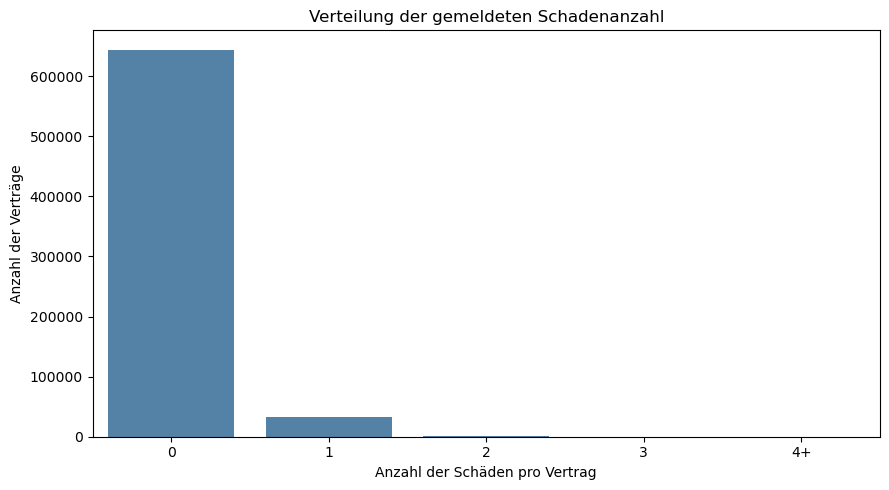

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Häufigkeitsverteilung der Schadenanzahl berechnen
schadenverteilung = freq["ClaimNb"].value_counts().sort_index()

# Anteil der Verträge ohne Schaden berechnen
anteil_ohne_schaden = (freq["ClaimNb"] == 0).mean() * 100

print(f"Anteil der Verträge ohne Schaden: {anteil_ohne_schaden:.2f} %")

# Schadenanzahl für eine übersichtliche Darstellung gruppieren
schadenklassen = freq["ClaimNb"].clip(upper=4)

haeufigkeiten = (
    schadenklassen.value_counts()
    .reindex(range(5), fill_value=0)
    .sort_index()
)

# Balkendiagramm erstellen
plt.figure(figsize=(9, 5))

sns.barplot(
    x=["0", "1", "2", "3", "4+"],
    y=haeufigkeiten.values,
    color="steelblue"
)

plt.title("Verteilung der gemeldeten Schadenanzahl")
plt.xlabel("Anzahl der Schäden pro Vertrag")
plt.ylabel("Anzahl der Verträge")
plt.tight_layout()
plt.show()

### Ergebnisse: Verteilung der Schadenanzahl

Die explorative Analyse zeigt, dass **94,98 % der Versicherungsverträge keinen gemeldeten Schaden** aufweisen. Verträge mit mehreren Schäden kommen deutlich seltener vor.

Die Zielvariable `ClaimNb` ist somit stark auf den Wert null konzentriert. Diese Verteilung muss bei der späteren statistischen Modellierung berücksichtigt werden.

Für die Berechnung der Schadenhäufigkeit wird zusätzlich die Exposition der Verträge berücksichtigt.

### 2.2 — Verteilung der Schadenhöhe

In diesem Schritt wird die Verteilung der Schadenbeträge untersucht. Ziel ist es, typische Schadenhöhen, die Streuung der Beträge und mögliche Extremwerte zu erkennen.

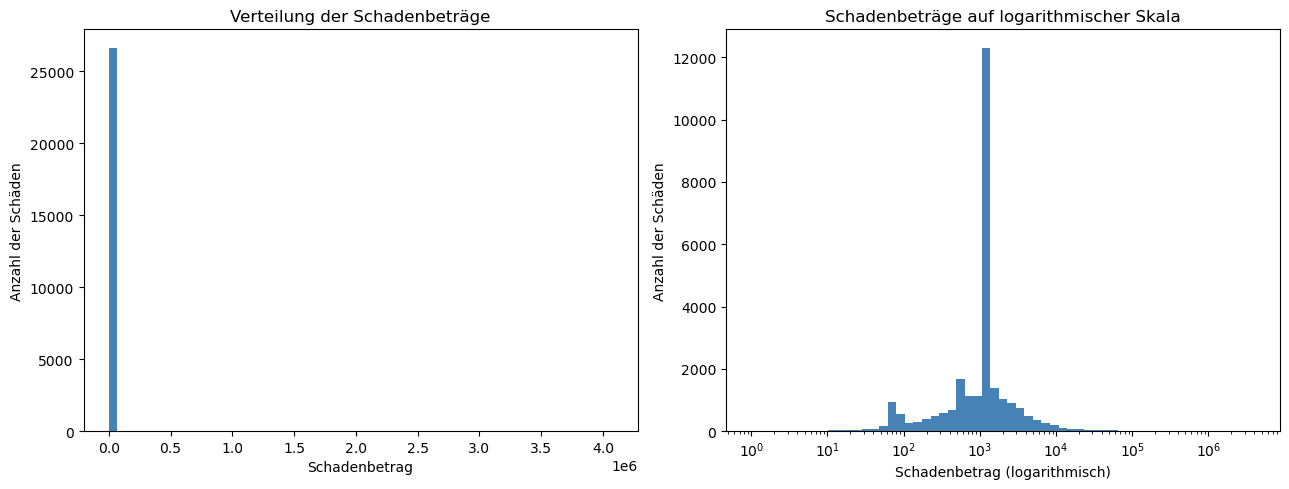

Median des Schadenbetrags: 1172.0
Mittelwert des Schadenbetrags: 2278.5363819963213
99. Perzentil: 16793.704399999988
Maximaler Schadenbetrag: 4075400.56


In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Verteilung der Schadenbeträge untersuchen
schadenbetraege = sev["ClaimAmount"]

fig, achsen = plt.subplots(1, 2, figsize=(13, 5))

# Histogramm der ursprünglichen Schadenbeträge
achsen[0].hist(schadenbetraege, bins=60, color="steelblue")
achsen[0].set_title("Verteilung der Schadenbeträge")
achsen[0].set_xlabel("Schadenbetrag")
achsen[0].set_ylabel("Anzahl der Schäden")

# Histogramm mit logarithmischer x-Achse
achsen[1].hist(
    schadenbetraege,
    bins=np.logspace(
        np.log10(schadenbetraege.min()),
        np.log10(schadenbetraege.max()),
        60
    ),
    color="steelblue"
)
achsen[1].set_xscale("log")
achsen[1].set_title("Schadenbeträge auf logarithmischer Skala")
achsen[1].set_xlabel("Schadenbetrag (logarithmisch)")
achsen[1].set_ylabel("Anzahl der Schäden")

plt.tight_layout()
plt.show()

# Zentrale Kennzahlen ausgeben
print("Median des Schadenbetrags:", schadenbetraege.median())
print("Mittelwert des Schadenbetrags:", schadenbetraege.mean())
print("99. Perzentil:", schadenbetraege.quantile(0.99))
print("Maximaler Schadenbetrag:", schadenbetraege.max())

### 2.3 — Analyse der höchsten Schadenbeträge

In diesem Schritt wird untersucht, welchen Anteil die höchsten Schadenbeträge an der gesamten Schadenhöhe haben. Ziel ist es, die Konzentration der Schadenkosten zu quantifizieren und die Bedeutung außergewöhnlich hoher Schäden für das Versicherungsportfolio besser zu verstehen.

In [52]:
# Gesamte Schadenhöhe berechnen
gesamtschaden = sev["ClaimAmount"].sum()

# Schwellenwert für die höchsten 1 % der Schäden bestimmen
grenzwert_99 = sev["ClaimAmount"].quantile(0.99)

# Schäden oberhalb des 99. Perzentils auswählen
hohe_schaeden = sev[sev["ClaimAmount"] > grenzwert_99]

# Anteil dieser Schäden an der gesamten Schadenhöhe berechnen
anteil_hoher_schaeden = (
    hohe_schaeden["ClaimAmount"].sum() / gesamtschaden * 100
)

print(f"Gesamte Schadenhöhe: {gesamtschaden:,.2f}")
print(f"Schwellenwert (99. Perzentil): {grenzwert_99:,.2f}")
print(f"Anzahl der Schäden oberhalb des Schwellenwerts: {len(hohe_schaeden)}")
print(f"Kostenanteil dieser Schäden: {anteil_hoher_schaeden:.2f} %")

# Die zehn höchsten Schadenbeträge anzeigen
print("\nDie zehn höchsten Schadenbeträge:")
display(
    sev.nlargest(10, "ClaimAmount")
)

Gesamte Schadenhöhe: 60,697,930.68
Schwellenwert (99. Perzentil): 16,793.70
Anzahl der Schäden oberhalb des Schwellenwerts: 267
Kostenanteil dieser Schäden: 37.96 %

Die zehn höchsten Schadenbeträge:


,IDpol,ClaimAmount
9756,1120377,4075400.56
15768,110846,1403057.40
11637,2141337,1301172.60
17992,3122016,774411.50
2869,2008127,390742.27
3307,3025890,369131.88
9999,1117644,307096.42
5521,158309,301635.49
18627,3075820,287423.00
18295,3150210,281897.49


### Ergebnisse: Konzentration der Schadenkosten

Die gesamte Schadenhöhe beträgt rund **60,70 Millionen**. Die **267 Schäden oberhalb des 99. Perzentils** machen lediglich etwa 1 % aller erfassten Schäden aus, verursachen jedoch **37,96 % der gesamten Schadenkosten**.

Dies zeigt eine starke Konzentration der Schadenkosten auf wenige außergewöhnlich hohe Schäden.

Aus betriebswirtschaftlicher Sicht unterstreicht dieses Ergebnis die Bedeutung der Überwachung von Großschäden für das Risikomanagement. Die Ursachen dieser Schäden können anhand der verfügbaren Daten jedoch nicht bestimmt werden.

### 2.4 — Analyse der Fahrermerkmale

In diesem Schritt werden das Alter der Fahrer und ihre Bonus-Malus-Werte untersucht. Ziel ist es, die Zusammensetzung des Versicherungsportfolios besser zu verstehen und auffällige Verteilungen zu erkennen.

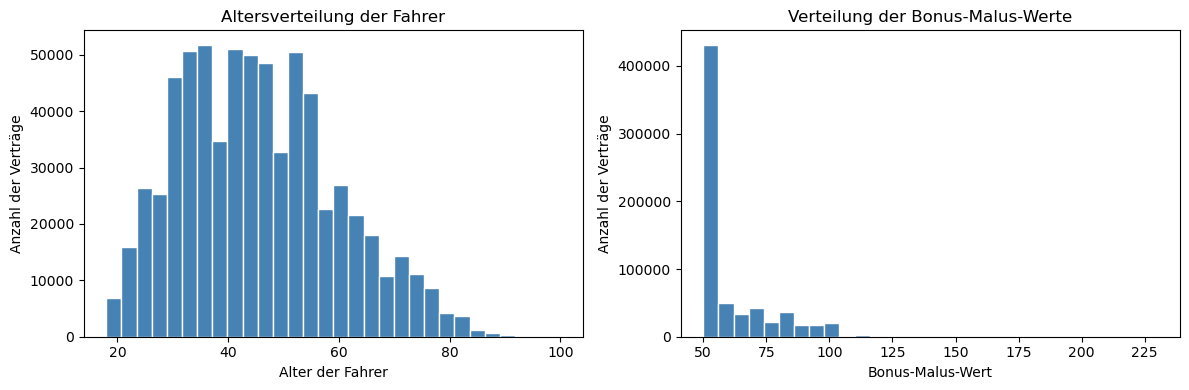

=== Kennzahlen der Fahrermerkmale ===


,DrivAge,BonusMalus
count,678013.00,678013.00
mean,45.50,59.76
std,14.14,15.64
min,18.00,50.00
25%,34.00,50.00
50%,44.00,50.00
75%,55.00,64.00
max,100.00,230.00


In [57]:
import matplotlib.pyplot as plt

# Verteilungen der Fahrermerkmale darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 4))

# Altersverteilung der Fahrer
achsen[0].hist(
    freq["DrivAge"],
    bins=30,
    color="steelblue",
    edgecolor="white"
)
achsen[0].set_title("Altersverteilung der Fahrer")
achsen[0].set_xlabel("Alter der Fahrer")
achsen[0].set_ylabel("Anzahl der Verträge")

# Verteilung der Bonus-Malus-Werte
achsen[1].hist(
    freq["BonusMalus"],
    bins=30,
    color="steelblue",
    edgecolor="white"
)
achsen[1].set_title("Verteilung der Bonus-Malus-Werte")
achsen[1].set_xlabel("Bonus-Malus-Wert")
achsen[1].set_ylabel("Anzahl der Verträge")

plt.tight_layout()
plt.show()

# Deskriptive Kennzahlen der Fahrermerkmale
print("=== Kennzahlen der Fahrermerkmale ===")
display(
    freq[["DrivAge", "BonusMalus"]]
    .describe()
    .round(2)
)

### Ergebnisse: Analyse der Fahrermerkmale

Das durchschnittliche Fahreralter beträgt **45,50 Jahre**, der Median liegt bei **44 Jahren**. Die meisten Versicherungsverträge entfallen auf Fahrer mittleren Alters. Sehr junge und ältere Fahrer sind im Datensatz weniger stark vertreten.

Der durchschnittliche Bonus-Malus-Wert beträgt **59,76**, während der Median bei **50** liegt. Ein großer Teil der Verträge weist den Wert 50 auf. Höhere Werte kommen deutlich seltener vor.

Diese Ergebnisse beschreiben zunächst die Zusammensetzung des Versicherungsportfolios. Aussagen über das tatsächliche Schadenrisiko einzelner Fahrergruppen erfordern eine zusätzliche Analyse der Schadenhäufigkeit unter Berücksichtigung der Exposition.

### 2.5 — Analyse der Fahrzeugmerkmale und Regionen

In diesem Schritt werden die Fahrzeugmerkmale und die geografische Verteilung des Versicherungsportfolios untersucht. Ziel ist es, die häufigsten Fahrzeugkategorien, Kraftstoffarten und Regionen zu identifizieren.

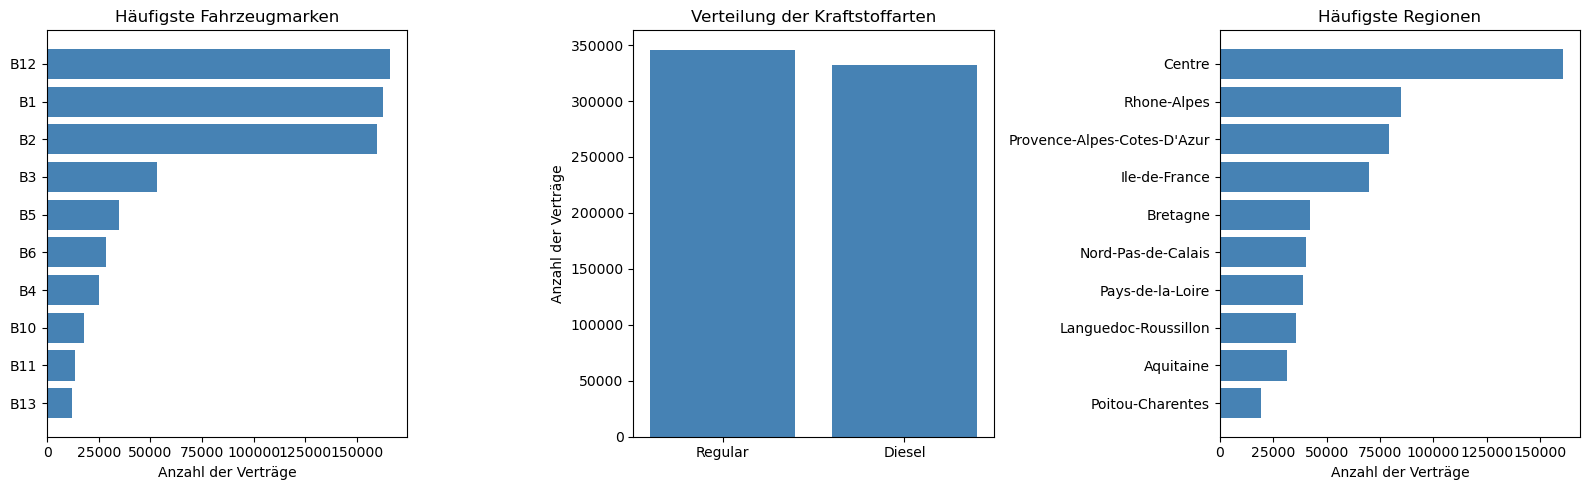

=== Fahrzeugmerkmale ===


,VehAge,VehPower
count,678013.00,678013.00
mean,7.04,6.45
std,5.67,2.05
min,0.00,4.00
25%,2.00,5.00
50%,6.00,6.00
75%,11.00,7.00
max,100.00,15.00


In [62]:
import matplotlib.pyplot as plt

# Häufigste Fahrzeugmarken und Regionen ermitteln
haeufige_marken = freq["VehBrand"].value_counts().head(10)
haeufige_regionen = freq["Region"].value_counts().head(10)

# Verteilung der Kraftstoffarten ermitteln
kraftstoffarten = freq["VehGas"].value_counts()

# Drei Diagramme erstellen
fig, achsen = plt.subplots(1, 3, figsize=(16, 5))

# Häufigste Fahrzeugmarken
achsen[0].barh(
    haeufige_marken.index,
    haeufige_marken.values,
    color="steelblue"
)
achsen[0].invert_yaxis()
achsen[0].set_title("Häufigste Fahrzeugmarken")
achsen[0].set_xlabel("Anzahl der Verträge")

# Verteilung der Kraftstoffarten
achsen[1].bar(
    kraftstoffarten.index,
    kraftstoffarten.values,
    color="steelblue"
)
achsen[1].set_title("Verteilung der Kraftstoffarten")
achsen[1].set_ylabel("Anzahl der Verträge")

# Häufigste Regionen
achsen[2].barh(
    haeufige_regionen.index,
    haeufige_regionen.values,
    color="steelblue"
)
achsen[2].invert_yaxis()
achsen[2].set_title("Häufigste Regionen")
achsen[2].set_xlabel("Anzahl der Verträge")

plt.tight_layout()
plt.show()

# Fahrzeugbezogene Kennzahlen
print("=== Fahrzeugmerkmale ===")
display(
    freq[["VehAge", "VehPower"]]
    .describe()
    .round(2)
)

### Ergebnisse: Fahrzeugmerkmale und regionale Verteilung

Die Fahrzeugkategorien **B12, B1 und B2** sind im Versicherungsportfolio am häufigsten vertreten. Fahrzeuge mit Benzinantrieb sind etwas häufiger als Dieselfahrzeuge.

Regional weist **Centre** die höchste Anzahl an Versicherungsverträgen auf.

Das durchschnittliche Fahrzeugalter beträgt **7,04 Jahre**, der Median liegt bei **6 Jahren**. Die durchschnittliche Fahrzeugleistungskennzahl beträgt **6,45**.

Diese Ergebnisse beschreiben die Zusammensetzung des Portfolios. Rückschlüsse auf das Schadenrisiko einzelner Fahrzeug- oder Regionalgruppen sind daraus noch nicht möglich.

### 2.6 — Zusammenhänge zwischen numerischen Variablen

n diesem Schritt werden die statistischen Zusammenhänge zwischen den numerischen Variablen untersucht. Eine Korrelationsmatrix hilft dabei, mögliche lineare Beziehungen zu erkennen. Die Ergebnisse werden explorativ interpretiert und erlauben keine kausalen Schlussfolgerungen.

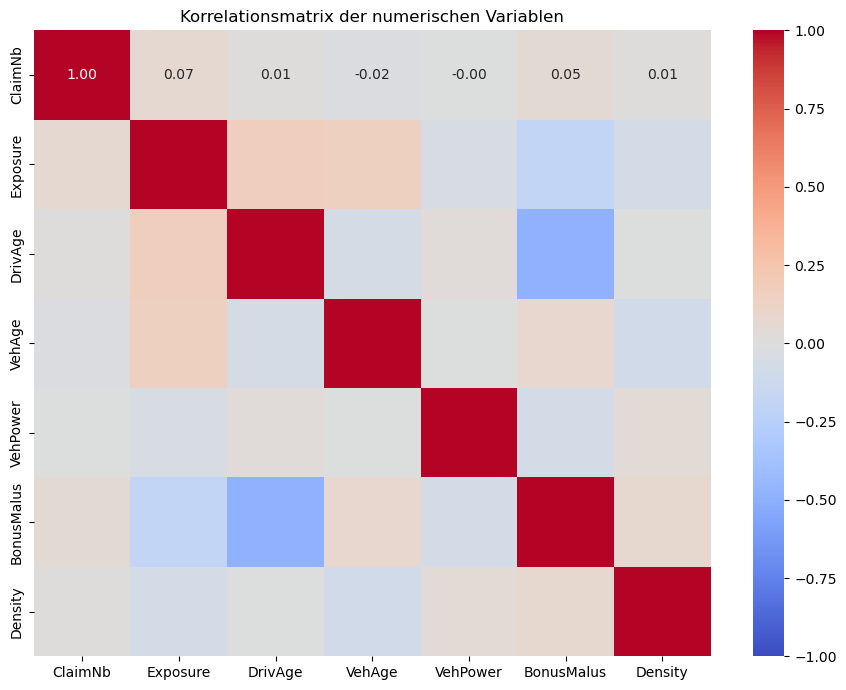

=== Korrelationen mit der Schadenanzahl ===


,Pearson-Korrelation
Exposure,0.068909
BonusMalus,0.050544
DrivAge,0.011392
Density,0.010754
VehPower,-0.004259
VehAge,-0.021768


In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Relevante numerische Variablen auswählen
numerische_variablen = [
    "ClaimNb",
    "Exposure",
    "DrivAge",
    "VehAge",
    "VehPower",
    "BonusMalus",
    "Density"
]

# Korrelationsmatrix nach Pearson berechnen
korrelationen = freq[numerische_variablen].corr(method="pearson")

# Korrelationsmatrix visualisieren
plt.figure(figsize=(9, 7))

sns.heatmap(
    korrelationen,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Korrelationsmatrix der numerischen Variablen")
plt.tight_layout()
plt.show()

# Korrelationen mit der Schadenanzahl anzeigen
print("=== Korrelationen mit der Schadenanzahl ===")

display(
    korrelationen["ClaimNb"]
    .drop("ClaimNb")
    .sort_values(ascending=False)
    .to_frame("Pearson-Korrelation")
)

### Ergebnisse: Korrelationsanalyse

Die Pearson-Korrelationsanalyse zeigt überwiegend sehr schwache lineare Zusammenhänge zwischen der Schadenanzahl (`ClaimNb`) und den untersuchten numerischen Variablen.

Die höchsten positiven Korrelationen bestehen mit der Exposition (**r = 0,069**) und dem Bonus-Malus-Wert (**r = 0,051**). Die übrigen Korrelationskoeffizienten liegen nahe null.

Eine schwache lineare Korrelation schließt jedoch nichtlineare Zusammenhänge oder Unterschiede zwischen Risikogruppen aus. Zudem wird die unterschiedliche Expositionsdauer durch die einfache Korrelationsanalyse nicht angemessen berücksichtigt.

Daher werden im nächsten Schritt expositionsbereinigte Schadenhäufigkeiten berechnet und verschiedene Risikosegmente verglichen.


### 3.1 — Analyse der Schadenhäufigkeit

In diesem Schritt wird die Schadenhäufigkeit des Versicherungsportfolios untersucht. Dabei wird die Anzahl der gemeldeten Schäden ins Verhältnis zur gesamten Exposition gesetzt.

Ziel ist es, die durchschnittliche jährliche Schadenhäufigkeit zu berechnen und eine Grundlage für spätere Vergleiche zwischen verschiedenen Risikogruppen zu schaffen.


In [71]:

# Gesamtzahl der gemeldeten Schäden berechnen
gesamte_schaeden = freq["ClaimNb"].sum()

# Gesamte Exposition des Versicherungsportfolios berechnen
gesamte_exposition = freq["Exposure"].sum()

# Jährliche Schadenhäufigkeit berechnen
schadenhaeufigkeit = gesamte_schaeden / gesamte_exposition

# Ergebnisse ausgeben
print("Gesamtzahl der Schäden:", gesamte_schaeden)
print(f"Gesamte Exposition: {gesamte_exposition:,.2f}")
print(f"Jährliche Schadenhäufigkeit: {schadenhaeufigkeit:.2%}")


Gesamtzahl der Schäden: 36102
Gesamte Exposition: 358,499.45
Jährliche Schadenhäufigkeit: 10.07%



### Ergebnisse: Analyse der Schadenhäufigkeit

Im Versicherungsportfolio wurden insgesamt **36.102 Schäden** bei einer gesamten Exposition von rund **358.499,45 Versicherungsjahren** erfasst.

Daraus ergibt sich eine jährliche Schadenhäufigkeit von **10,07 %**. Dies entspricht ungefähr 10 Schäden pro 100 Versicherungsjahre.

Die Schadenhäufigkeit berücksichtigt die unterschiedliche Expositionsdauer der Versicherungsverträge und ermöglicht dadurch aussagekräftigere Risikovergleiche.

Aus versicherungswirtschaftlicher Sicht dient dieser Wert als Referenz für die spätere Analyse verschiedener Fahrer-, Fahrzeug- und Risikogruppen.



### 3.2 — Schadenhäufigkeit nach Fahreralter

In diesem Schritt wird untersucht, wie sich die Schadenhäufigkeit zwischen verschiedenen Altersgruppen der Fahrer unterscheidet.

Ziel ist es, mögliche Risikounterschiede zu erkennen und die jährliche Schadenhäufigkeit unter Berücksichtigung der Exposition zu vergleichen.


,Anzahl_Vertraege,Anzahl_Schaeden,Exposition,Schadenhaeufigkeit
Altersgruppe,,,,
18–25,38895,2841,16227.9033,0.1751
26–35,149183,6662,69266.7781,0.0962
36–45,170352,8397,87702.3363,0.0957
46–55,161899,9256,89268.7764,0.1037
56–65,90691,4748,51775.5533,0.0917
66+,66993,4198,44258.0982,0.0949


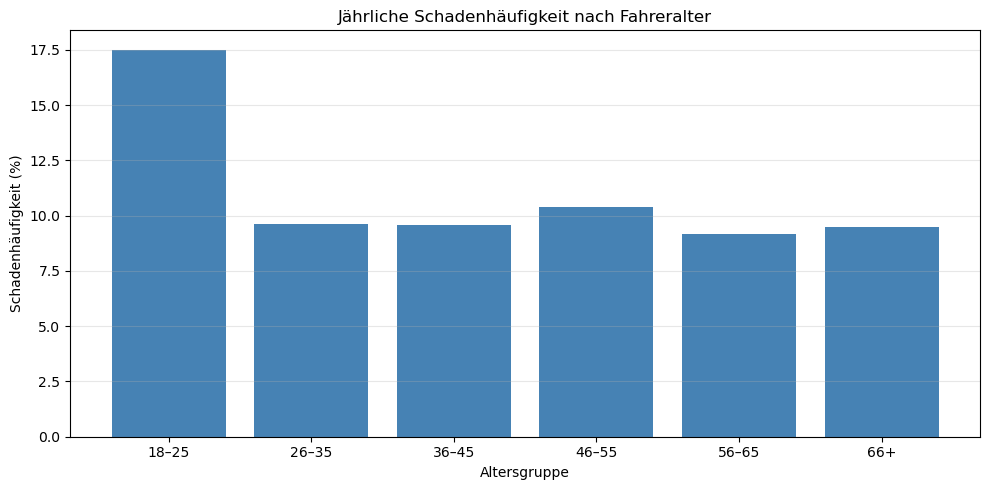

In [75]:

import pandas as pd
import matplotlib.pyplot as plt

# Altersgruppen der Fahrer definieren
altersgrenzen = [17, 25, 35, 45, 55, 65, 110]
alterslabels = ["18–25", "26–35", "36–45",
                "46–55", "56–65", "66+"]

# Fahrer den Altersgruppen zuordnen
freq["Altersgruppe"] = pd.cut(
    freq["DrivAge"],
    bins=altersgrenzen,
    labels=alterslabels
)

# Schäden und Exposition nach Altersgruppe aggregieren
schaden_nach_alter = freq.groupby(
    "Altersgruppe", observed=True
).agg(
    Anzahl_Vertraege=("IDpol", "count"),
    Anzahl_Schaeden=("ClaimNb", "sum"),
    Exposition=("Exposure", "sum")
)

# Jährliche Schadenhäufigkeit berechnen
schaden_nach_alter["Schadenhaeufigkeit"] = (
    schaden_nach_alter["Anzahl_Schaeden"]
    / schaden_nach_alter["Exposition"]
)

# Ergebnisse anzeigen
display(schaden_nach_alter.round(4))

# Schadenhäufigkeit nach Altersgruppe visualisieren
plt.figure(figsize=(10, 5))

plt.bar(
    schaden_nach_alter.index.astype(str),
    schaden_nach_alter["Schadenhaeufigkeit"] * 100,
    color="steelblue"
)

plt.title("Jährliche Schadenhäufigkeit nach Fahreralter")
plt.xlabel("Altersgruppe")
plt.ylabel("Schadenhäufigkeit (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### Ergebnisse: Schadenhäufigkeit nach Fahreralter

Die Analyse zeigt deutliche Unterschiede in der jährlichen Schadenhäufigkeit zwischen den Altersgruppen.

Die Fahrer im Alter von **18 bis 25 Jahren** weisen mit **17,51 %** die höchste Schadenhäufigkeit auf.

Bei den übrigen Altersgruppen liegt die Schadenhäufigkeit zwischen **9,17 % und 10,37 %**.

Die niedrigste Schadenhäufigkeit wurde bei den Fahrern zwischen **56 und 65 Jahren** mit **9,17 %** beobachtet.

Aus versicherungswirtschaftlicher Sicht deutet dies darauf hin, dass jüngere Fahrer im untersuchten Portfolio ein erhöhtes Schadenrisiko aufweisen könnten.

Allerdings beschreibt diese Analyse zunächst nur einen Zusammenhang. Weitere Einflussfaktoren wie Bonus-Malus, Fahrzeugmerkmale und Region müssen berücksichtigt werden, bevor belastbare Schlussfolgerungen gezogen werden können.



### 3.3 — Schadenhäufigkeit nach Bonus-Malus

In diesem Schritt wird untersucht, wie sich die jährliche Schadenhäufigkeit zwischen verschiedenen Bonus-Malus-Gruppen unterscheidet.

Ziel ist es, mögliche Risikounterschiede zu erkennen und den Zusammenhang zwischen dem Bonus-Malus-Wert und der Schadenhäufigkeit zu analysieren.


,Anzahl_Vertraege,Anzahl_Schaeden,Exposition,Schadenhaeufigkeit
BonusMalusGruppe,,,,
50,384156,18056,225233.1309,0.0802
51–75,175012,9614,84874.6573,0.1133
76–100,111051,7090,44820.3383,0.1582
101–125,6987,1178,3198.2661,0.3683
126–150,598,110,277.9247,0.3958
151–230,209,54,95.1282,0.5677


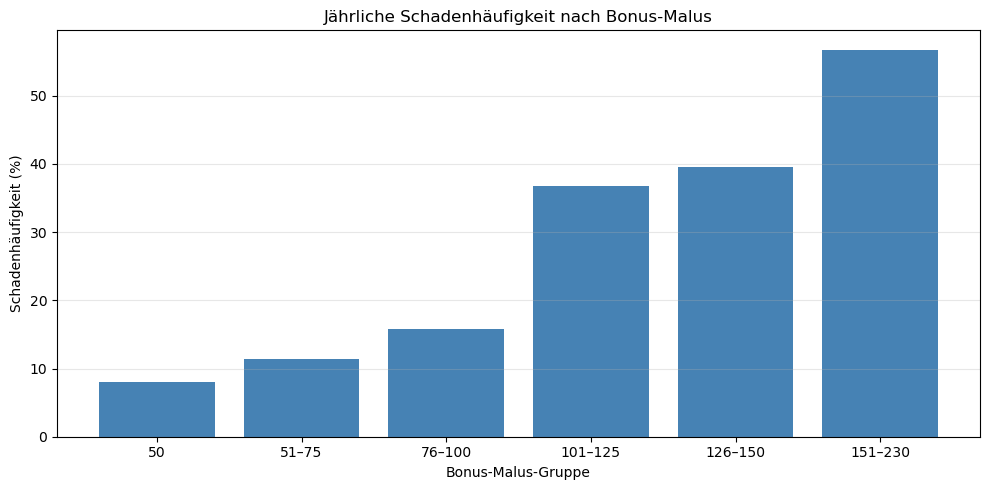

In [79]:

import pandas as pd
import matplotlib.pyplot as plt

# Bonus-Malus-Gruppen definieren
bonus_grenzen = [49, 50, 75, 100, 125, 150, 230]
bonus_labels = [
    "50", "51–75", "76–100",
    "101–125", "126–150", "151–230"
]

# Bonus-Malus-Werte gruppieren
freq["BonusMalusGruppe"] = pd.cut(
    freq["BonusMalus"],
    bins=bonus_grenzen,
    labels=bonus_labels
)

# Schäden und Exposition je Gruppe aggregieren
schaden_nach_bonus = freq.groupby(
    "BonusMalusGruppe", observed=True
).agg(
    Anzahl_Vertraege=("IDpol", "count"),
    Anzahl_Schaeden=("ClaimNb", "sum"),
    Exposition=("Exposure", "sum")
)

# Jährliche Schadenhäufigkeit berechnen
schaden_nach_bonus["Schadenhaeufigkeit"] = (
    schaden_nach_bonus["Anzahl_Schaeden"]
    / schaden_nach_bonus["Exposition"]
)

# Ergebnisse anzeigen
display(schaden_nach_bonus.round(4))

# Schadenhäufigkeit visualisieren
plt.figure(figsize=(10, 5))

plt.bar(
    schaden_nach_bonus.index.astype(str),
    schaden_nach_bonus["Schadenhaeufigkeit"] * 100,
    color="steelblue"
)

plt.title("Jährliche Schadenhäufigkeit nach Bonus-Malus")
plt.xlabel("Bonus-Malus-Gruppe")
plt.ylabel("Schadenhäufigkeit (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### Ergebnisse: Schadenhäufigkeit nach Bonus-Malus

Die Analyse zeigt, dass die jährliche Schadenhäufigkeit mit steigendem Bonus-Malus-Wert deutlich zunimmt.

Die Gruppe mit einem Bonus-Malus-Wert von **50** weist mit **8,02 %** die niedrigste Schadenhäufigkeit auf.

Bei einem Bonus-Malus-Wert zwischen **76 und 100** beträgt die Schadenhäufigkeit bereits **15,82 %**.

Die höchste Schadenhäufigkeit zeigt die Gruppe **151–230** mit **56,77 %**.

Allerdings enthalten die Gruppen mit sehr hohen Bonus-Malus-Werten deutlich weniger Versicherungsverträge. Ihre Ergebnisse sollten daher vorsichtig interpretiert werden.

Aus versicherungswirtschaftlicher Sicht ist Bonus-Malus ein relevanter Indikator für die Risikosegmentierung. Die beobachteten Unterschiede zeigen jedoch keinen kausalen Zusammenhang.



### 3.4 — Schadenhäufigkeit nach Fahrzeugalter

In diesem Schritt wird untersucht, wie sich die jährliche Schadenhäufigkeit zwischen verschiedenen Fahrzeugaltersgruppen unterscheidet.

Ziel ist es, mögliche Risikounterschiede zu erkennen und zu analysieren, ob das Fahrzeugalter mit der Schadenhäufigkeit zusammenhängt.

Dabei wird die Anzahl der gemeldeten Schäden durch die gesamte Exposition der jeweiligen Gruppe geteilt.


,Anzahl_Vertraege,Anzahl_Schaeden,Exposition,Schadenhaeufigkeit
Fahrzeugaltersgruppe,,,,
0–1,129023,8136,49468.5663,0.1645
2–3,109385,5088,55788.8719,0.0912
4–5,82229,4423,45958.7409,0.0962
6–10,171594,9846,99008.9164,0.0994
11–20,177460,8333,103127.1340,0.0808
21+,8322,276,5147.2160,0.0536


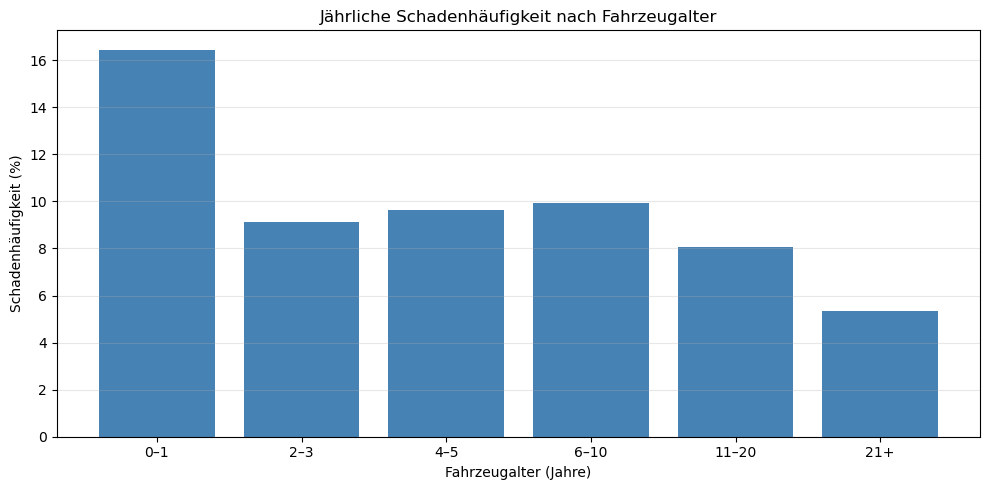

In [83]:

import pandas as pd
import matplotlib.pyplot as plt

# Fahrzeugaltersgruppen definieren
fahrzeug_grenzen = [-1, 1, 3, 5, 10, 20, 100]
fahrzeug_labels = [
    "0–1", "2–3", "4–5",
    "6–10", "11–20", "21+"
]

# Fahrzeuge den Altersgruppen zuordnen
freq["Fahrzeugaltersgruppe"] = pd.cut(
    freq["VehAge"],
    bins=fahrzeug_grenzen,
    labels=fahrzeug_labels
)

# Schäden und Exposition je Altersgruppe aggregieren
schaden_nach_fahrzeugalter = freq.groupby(
    "Fahrzeugaltersgruppe", observed=True
).agg(
    Anzahl_Vertraege=("IDpol", "count"),
    Anzahl_Schaeden=("ClaimNb", "sum"),
    Exposition=("Exposure", "sum")
)

# Jährliche Schadenhäufigkeit berechnen
schaden_nach_fahrzeugalter["Schadenhaeufigkeit"] = (
    schaden_nach_fahrzeugalter["Anzahl_Schaeden"]
    / schaden_nach_fahrzeugalter["Exposition"]
)

# Ergebnisse anzeigen
display(schaden_nach_fahrzeugalter.round(4))

# Schadenhäufigkeit visualisieren
plt.figure(figsize=(10, 5))

plt.bar(
    schaden_nach_fahrzeugalter.index.astype(str),
    schaden_nach_fahrzeugalter["Schadenhaeufigkeit"] * 100,
    color="steelblue"
)

plt.title("Jährliche Schadenhäufigkeit nach Fahrzeugalter")
plt.xlabel("Fahrzeugalter (Jahre)")
plt.ylabel("Schadenhäufigkeit (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### Ergebnisse: Schadenhäufigkeit nach Fahrzeugalter

Die Analyse zeigt Unterschiede in der jährlichen Schadenhäufigkeit zwischen den Fahrzeugaltersgruppen.

Die Gruppe der **0 bis 1 Jahre alten Fahrzeuge** weist mit **16,45 %** die höchste Schadenhäufigkeit auf.

Bei Fahrzeugen zwischen **2 und 10 Jahren** liegt die Schadenhäufigkeit zwischen **9,12 % und 9,94 %**.

Die niedrigste Schadenhäufigkeit wurde bei Fahrzeugen ab **21 Jahren** mit **5,36 %** beobachtet.

Aus versicherungswirtschaftlicher Sicht deutet dies darauf hin, dass das Fahrzeugalter ein relevanter Faktor für die Risikosegmentierung sein könnte.

Allerdings können weitere Faktoren wie Fahreralter, Bonus-Malus, Fahrzeugnutzung und Region die beobachteten Unterschiede beeinflussen.

Die Ergebnisse zeigen daher einen deskriptiven Zusammenhang und keinen kausalen Effekt des Fahrzeugalters.



### 3.5 — Schadenhäufigkeit nach Region

In diesem Schritt wird die jährliche Schadenhäufigkeit in den verschiedenen Regionen untersucht.

Ziel ist es, regionale Unterschiede im Schadenrisiko zu erkennen und mögliche geografische Risikosegmente zu identifizieren.

Dabei wird die Anzahl der gemeldeten Schäden durch die gesamte Exposition der jeweiligen Region geteilt, um einen vergleichbaren Risikoindikator zu erhalten.


,Anzahl_Vertraege,Anzahl_Schaeden,Exposition,Schadenhaeufigkeit
Region,,,,
Corse,4516,247,1765.9354,0.1399
Champagne-Ardenne,3026,160,1205.8315,0.1327
Ile-de-France,69791,3978,30208.6420,0.1317
Picardie,7994,439,3574.4102,0.1228
Rhone-Alpes,84752,5032,45347.4173,0.1110
Alsace,2200,133,1209.1158,0.1100
Provence-Alpes-Cotes-D'Azur,79315,3907,35790.3210,0.1092
Limousin,4567,259,2395.9945,0.1081
Languedoc-Roussillon,35805,1547,14736.1042,0.1050


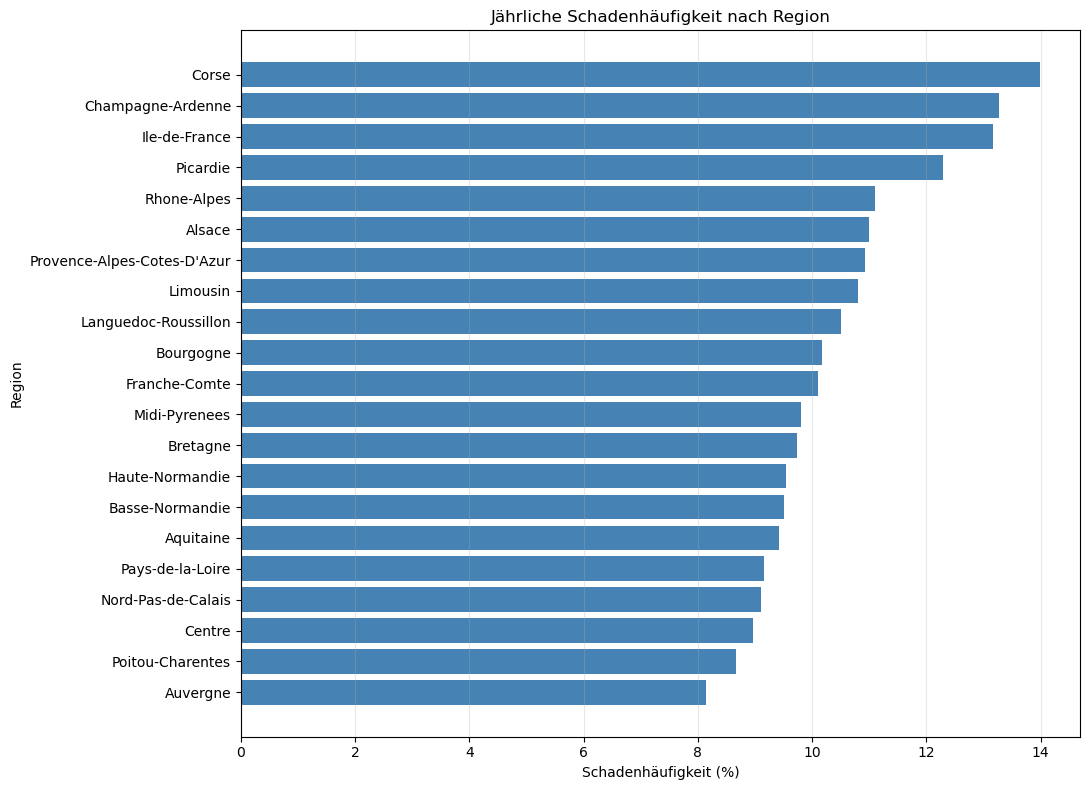

In [87]:

import matplotlib.pyplot as plt

# Anzahl der Verträge, Schäden und Exposition nach Region berechnen
schaden_nach_region = freq.groupby("Region").agg(
    Anzahl_Vertraege=("IDpol", "count"),
    Anzahl_Schaeden=("ClaimNb", "sum"),
    Exposition=("Exposure", "sum")
)

# Jährliche Schadenhäufigkeit je Region berechnen
schaden_nach_region["Schadenhaeufigkeit"] = (
    schaden_nach_region["Anzahl_Schaeden"]
    / schaden_nach_region["Exposition"]
)

# Regionen nach Schadenhäufigkeit sortieren
schaden_nach_region = schaden_nach_region.sort_values(
    "Schadenhaeufigkeit", ascending=False
)

# Ergebnisse anzeigen
display(schaden_nach_region.round(4))

# Schadenhäufigkeit nach Region visualisieren
plt.figure(figsize=(11, 8))

plt.barh(
    schaden_nach_region.index,
    schaden_nach_region["Schadenhaeufigkeit"] * 100,
    color="steelblue"
)

plt.title("Jährliche Schadenhäufigkeit nach Region")
plt.xlabel("Schadenhäufigkeit (%)")
plt.ylabel("Region")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



### Ergebnisse: Schadenhäufigkeit nach Region

Die Analyse zeigt regionale Unterschiede in der jährlichen Schadenhäufigkeit.

Die höchste Schadenhäufigkeit wurde in **Corse** mit **13,99 %** festgestellt, gefolgt von **Champagne-Ardenne** mit **13,27 %** und **Ile-de-France** mit **13,17 %**.

Die niedrigste Schadenhäufigkeit weist **Auvergne** mit **8,14 %** auf. Auch **Poitou-Charentes** mit **8,67 %** und **Centre** mit **8,96 %** liegen unter dem Durchschnitt des gesamten Versicherungsportfolios von **10,07 %**.

Die Anzahl der Versicherungsverträge unterscheidet sich deutlich zwischen den Regionen. Beispielsweise umfasst Centre mehr als 160.000 Verträge, während Champagne-Ardenne nur rund 3.000 Verträge enthält.

Aus versicherungswirtschaftlicher Sicht können regionale Unterschiede bei der Risikosegmentierung und beim Schadenmanagement berücksichtigt werden.

Allerdings können weitere Einflussfaktoren wie Fahreralter, Bonus-Malus und Fahrzeugmerkmale die beobachteten Unterschiede beeinflussen. Die Ergebnisse zeigen daher zunächst deskriptive Zusammenhänge.



### 3.6 — Analyse der Schadenhöhe (Claim Severity)

In diesem Abschnitt wird die Höhe der gemeldeten Versicherungsschäden untersucht. Während die bisherige Analyse der Schadenhäufigkeit gezeigt hat, wie oft Schäden auftreten, konzentriert sich die Schadenhöhenanalyse auf die finanziellen Auswirkungen einzelner Schäden.

Ziel ist es, die durchschnittliche und mediane Schadenhöhe zu berechnen, die Verteilung der Schadenbeträge zu analysieren und besonders hohe Schäden zu identifizieren.

Die Analyse basiert auf dem Datensatz `sev`, der die einzelnen Schadenbeträge (`ClaimAmount`) enthält.

Aus versicherungswirtschaftlicher Sicht ist die Schadenhöhe ein wichtiger Indikator zur Bewertung des finanziellen Risikos eines Versicherungsportfolios. Zusammen mit der Schadenhäufigkeit bildet sie eine Grundlage für die weitere Risikoanalyse.



#### 3.6.1 — Durchschnittliche und mediane Schadenhöhe

In diesem Schritt werden die durchschnittliche und die mediane Schadenhöhe des Versicherungsportfolios berechnet.

Ziel ist es, die typischen Schadenkosten zu untersuchen und mögliche Unterschiede zwischen dem Mittelwert und dem Median zu erkennen.

Ein deutlicher Unterschied zwischen beiden Kennzahlen kann darauf hinweisen, dass einzelne besonders hohe Schäden den Durchschnitt beeinflussen.


In [92]:

# Gesamtzahl der erfassten Schadenbeträge berechnen
anzahl_schaeden = sev["ClaimAmount"].count()

# Gesamte Schadenkosten berechnen
gesamte_schadenkosten = sev["ClaimAmount"].sum()

# Durchschnittliche Schadenhöhe berechnen
durchschnittliche_schadenhoehe = sev["ClaimAmount"].mean()

# Mediane Schadenhöhe berechnen
mediane_schadenhoehe = sev["ClaimAmount"].median()

# Ergebnisse ausgeben
print("Anzahl der erfassten Schadenbeträge:", anzahl_schaeden)
print(f"Gesamte Schadenkosten: {gesamte_schadenkosten:,.2f} €")
print(f"Durchschnittliche Schadenhöhe: {durchschnittliche_schadenhoehe:,.2f} €")
print(f"Mediane Schadenhöhe: {mediane_schadenhoehe:,.2f} €")


Anzahl der erfassten Schadenbeträge: 26639
Gesamte Schadenkosten: 60,697,930.68 €
Durchschnittliche Schadenhöhe: 2,278.54 €
Mediane Schadenhöhe: 1,172.00 €



#### Ergebnisse: Durchschnittliche und mediane Schadenhöhe

Im Datensatz wurden insgesamt **26.639 Schadenbeträge** mit gesamten Schadenkosten von rund **60,70 Millionen Euro** erfasst.

Die durchschnittliche Schadenhöhe beträgt **2.278,54 €**, während die mediane Schadenhöhe bei **1.172,00 €** liegt.

Der Mittelwert ist damit deutlich höher als der Median. Dies deutet darauf hin, dass einzelne besonders hohe Schadenbeträge den Durchschnitt stark beeinflussen.

Aus versicherungswirtschaftlicher Sicht ist es daher sinnvoll, neben dem Durchschnitt auch den Median zu betrachten, um die typische Schadenhöhe besser einschätzen zu können.

Die Ergebnisse beziehen sich auf die im Datensatz `sev` erfassten Schadenbeträge.



#### 3.6.2 — Verteilung der Schadenhöhe

In diesem Schritt wird die Verteilung der einzelnen Schadenbeträge untersucht.

Ziel ist es, die Streuung der Schadenhöhen zu analysieren und mögliche Ausreißer zu erkennen. Dazu werden ein Histogramm und ein Boxplot erstellt.

Da einzelne sehr hohe Schadenbeträge die Darstellung beeinflussen können, wird zusätzlich eine logarithmische Skalierung verwendet.


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


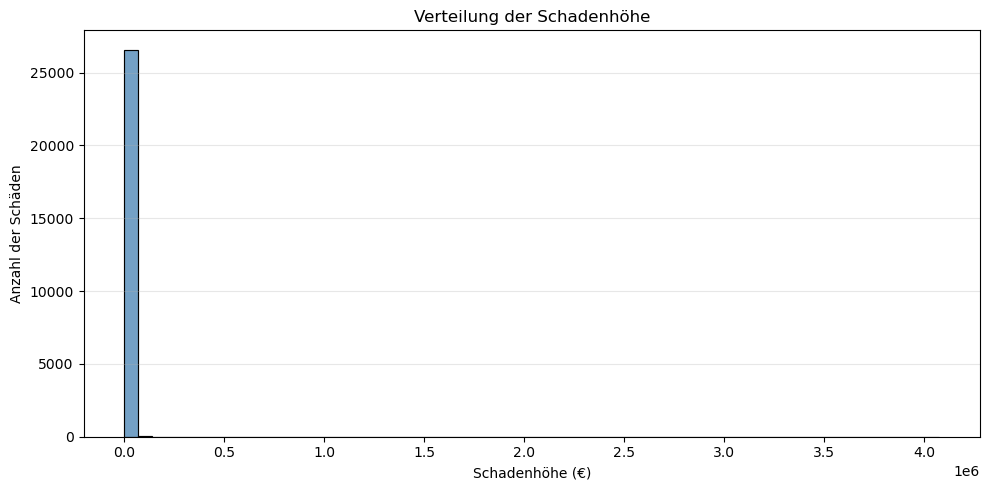

In [96]:

import matplotlib.pyplot as plt
import seaborn as sns

# Verteilung der Schadenbeträge darstellen
plt.figure(figsize=(10, 5))

sns.histplot(
    data=sev,
    x="ClaimAmount",
    bins=60,
    color="steelblue"
)

plt.title("Verteilung der Schadenhöhe")
plt.xlabel("Schadenhöhe (€)")
plt.ylabel("Anzahl der Schäden")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


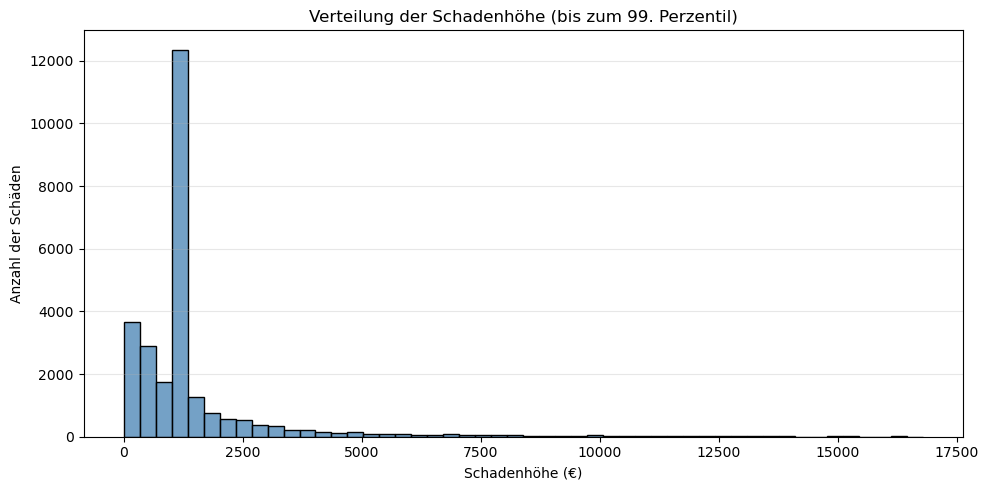

In [98]:

# 99. Perzentil der Schadenbeträge berechnen
grenze_99 = sev["ClaimAmount"].quantile(0.99)

# Schadenbeträge bis zum 99. Perzentil auswählen
schaeden_bis_99 = sev[
    sev["ClaimAmount"] <= grenze_99
]

# Verteilung ohne die höchsten 1 % visualisieren
plt.figure(figsize=(10, 5))

sns.histplot(
    data=schaeden_bis_99,
    x="ClaimAmount",
    bins=50,
    color="steelblue"
)

plt.title("Verteilung der Schadenhöhe (bis zum 99. Perzentil)")
plt.xlabel("Schadenhöhe (€)")
plt.ylabel("Anzahl der Schäden")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



#### Interpretation der Schadenhöhenverteilung

Das erste Histogramm zeigt eine stark rechtsschiefe Verteilung der Schadenbeträge. Die meisten Schäden konzentrieren sich auf vergleichsweise niedrige Beträge, während einzelne sehr hohe Schäden die Darstellung stark beeinflussen.

Um die Verteilung der typischen Schadenbeträge besser zu erkennen, wurde ein zweites Histogramm erstellt, das nur Schadenbeträge bis zum 99. Perzentil berücksichtigt.

Die besonders hohen Schäden wurden dabei nicht aus dem Datensatz entfernt, sondern lediglich für die Visualisierung ausgeblendet.

Aus versicherungswirtschaftlicher Sicht zeigt dies, dass neben den häufigeren kleineren Schäden auch seltene, besonders kostenintensive Schadenereignisse berücksichtigt werden müssen.



#### Boxplot aller Schadenbeträge

Um die Verteilung der Schadenhöhen genauer zu untersuchen, wird zunächst ein Boxplot aller erfassten Schadenbeträge erstellt.

Ziel ist es, den Median, die Streuung und mögliche Ausreißer sichtbar zu machen.


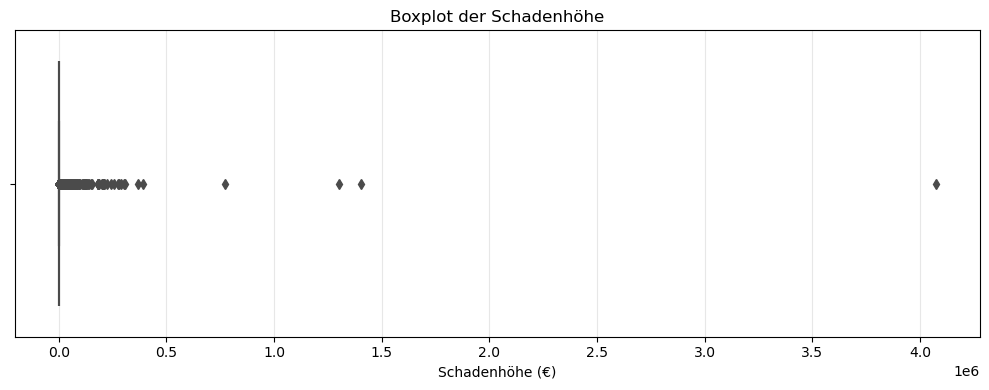

In [102]:

# Boxplot aller Schadenbeträge erstellen
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=sev["ClaimAmount"],
    color="steelblue"
)

plt.title("Boxplot der Schadenhöhe")
plt.xlabel("Schadenhöhe (€)")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation:**

Der Boxplot zeigt, dass einzelne sehr hohe Schadenbeträge die Darstellung stark beeinflussen.

Die Box erscheint im Vergleich zur gesamten Spannweite sehr klein. Dadurch sind der Median und die Quartile kaum erkennbar.

Dies bestätigt die stark rechtsschiefe Verteilung der Schadenbeträge.

Um die Verteilung der typischen Schadenhöhen besser sichtbar zu machen, wird im nächsten Schritt ein zweiter Boxplot erstellt.



#### Boxplot der Schadenhöhe bis zum 99. Perzentil

Da einzelne extreme Schadenbeträge die Darstellung des ersten Boxplots stark beeinflussen, wird die Analyse auf Schadenbeträge bis zum 99. Perzentil begrenzt.

Ziel ist es, den Median, die Quartile und die Streuung der übrigen Schadenbeträge besser zu erkennen.


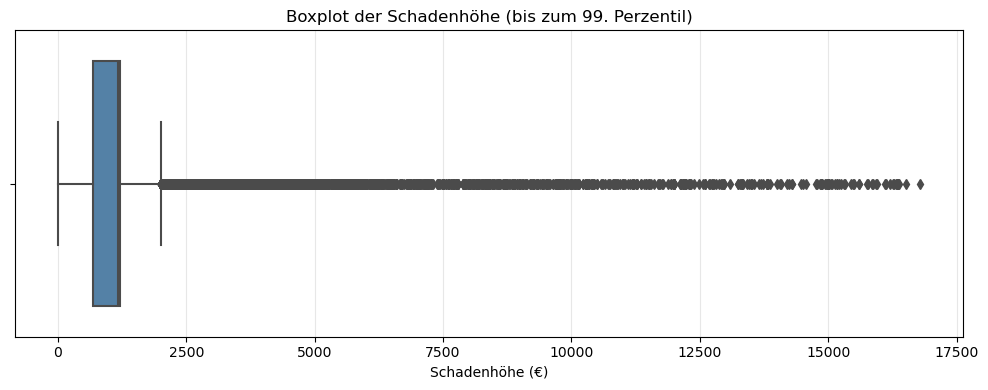

In [106]:

# 99. Perzentil der Schadenbeträge berechnen
grenze_99 = sev["ClaimAmount"].quantile(0.99)

# Schadenbeträge bis zum 99. Perzentil auswählen
schaeden_bis_99 = sev[
    sev["ClaimAmount"] <= grenze_99
]

# Boxplot bis zum 99. Perzentil erstellen
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=schaeden_bis_99["ClaimAmount"],
    color="steelblue"
)

plt.title("Boxplot der Schadenhöhe (bis zum 99. Perzentil)")
plt.xlabel("Schadenhöhe (€)")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation:**

Durch die Begrenzung auf das 99. Perzentil wird die Verteilung der Schadenbeträge besser sichtbar.

Der Median und die Quartile lassen sich nun deutlicher erkennen. Gleichzeitig zeigt der Boxplot, dass auch innerhalb dieses Wertebereichs höhere Schadenbeträge und mögliche Ausreißer auftreten.

Die höchsten 1 % der Schadenbeträge wurden nicht aus dem ursprünglichen Datensatz entfernt, sondern lediglich für diese Visualisierung ausgeschlossen.

Aus versicherungswirtschaftlicher Sicht zeigt die Analyse, dass sowohl typische als auch besonders hohe Schadenbeträge für die Bewertung des finanziellen Risikos relevant sind.



#### 3.6.3 — Analyse hoher Schadenbeträge (Large Loss Analysis)

In diesem Schritt wird untersucht, welchen Einfluss besonders hohe Schadenbeträge auf die gesamten Schadenkosten des Versicherungsportfolios haben.

Ziel ist es, die teuersten 1 % der erfassten Schäden zu identifizieren und ihren Anteil an den gesamten Schadenkosten zu berechnen.

Diese Analyse hilft dabei, die finanzielle Bedeutung seltener, aber besonders kostenintensiver Schadenereignisse besser zu verstehen.


In [110]:

# 99. Perzentil der Schadenbeträge berechnen
grenze_99 = sev["ClaimAmount"].quantile(0.99)

# Besonders hohe Schäden identifizieren
grosse_schaeden = sev[
    sev["ClaimAmount"] > grenze_99
]

# Gesamte Schadenkosten berechnen
gesamte_schadenkosten = sev["ClaimAmount"].sum()

# Kosten der besonders hohen Schäden berechnen
kosten_grosse_schaeden = grosse_schaeden["ClaimAmount"].sum()

# Anteil an den gesamten Schadenkosten berechnen
anteil_grosse_schaeden = (
    kosten_grosse_schaeden / gesamte_schadenkosten
) * 100

# Ergebnisse ausgeben
print(f"99. Perzentil: {grenze_99:,.2f} €")
print("Anzahl großer Schäden:", len(grosse_schaeden))
print(f"Kosten großer Schäden: {kosten_grosse_schaeden:,.2f} €")
print(f"Anteil an den Gesamtkosten: {anteil_grosse_schaeden:.2f} %")


99. Perzentil: 16,793.70 €
Anzahl großer Schäden: 267
Kosten großer Schäden: 23,038,549.76 €
Anteil an den Gesamtkosten: 37.96 %


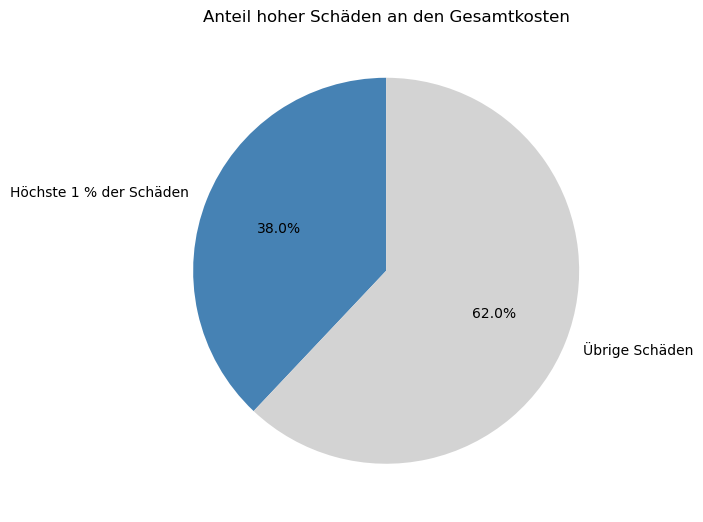

In [112]:

# Kostenanteile für die Visualisierung vorbereiten
kosten_uebrige_schaeden = (
    gesamte_schadenkosten - kosten_grosse_schaeden
)

# Kreisdiagramm erstellen
plt.figure(figsize=(7, 7))

plt.pie(
    [kosten_grosse_schaeden, kosten_uebrige_schaeden],
    labels=["Höchste 1 % der Schäden", "Übrige Schäden"],
    autopct="%1.1f%%",
    colors=["steelblue", "lightgray"],
    startangle=90
)

plt.title("Anteil hoher Schäden an den Gesamtkosten")
plt.tight_layout()
plt.show()



#### Ergebnisse: Analyse hoher Schadenbeträge

Die Analyse zeigt, dass die teuersten **1 % der erfassten Schäden** rund **37,96 % der gesamten Schadenkosten** verursachen.

Damit konzentriert sich ein erheblicher Teil der finanziellen Belastung des Versicherungsportfolios auf eine sehr kleine Anzahl besonders hoher Schäden.

Aus versicherungswirtschaftlicher Sicht verdeutlicht dieses Ergebnis die Bedeutung großer Schadenereignisse für das finanzielle Risiko eines Versicherers.

Solche Schäden können die gesamten Schadenkosten stark beeinflussen und sollten deshalb bei der Risikobewertung, Schadenüberwachung und Versicherungsplanung besonders berücksichtigt werden.

Die Ergebnisse beziehen sich ausschließlich auf die im Datensatz `sev` erfassten Schadenbeträge.



#### 3.6.4 — Schadenhöhe nach Risikosegmenten

In diesem Abschnitt wird untersucht, wie sich die Schadenhöhe zwischen verschiedenen Risikogruppen unterscheidet.

Ziel ist es, mögliche Unterschiede in den durchschnittlichen Schadenkosten zu identifizieren und die finanzielle Bedeutung einzelner Risikosegmente besser zu verstehen.

Dazu werden die Datensätze `freq` und `sev` über die gemeinsame Vertragsnummer `IDpol` miteinander verknüpft.

Anschließend wird die Schadenhöhe zunächst nach Fahreralter analysiert.


In [116]:

# Schadenbeträge mit den Vertragsmerkmalen verknüpfen
schaden_daten = sev.merge(
    freq[["IDpol", "DrivAge", "BonusMalus", "VehAge", "Region"]],
    on="IDpol",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verknüpfung überprüfen
print(schaden_daten["_merge"].value_counts())

# Nicht zugeordnete Schadenbeträge untersuchen
nicht_zugeordnet = schaden_daten[
    schaden_daten["_merge"] == "left_only"
]

print("Nicht zugeordnete Schäden:", len(nicht_zugeordnet))
print(f"Nicht zugeordnete Schadenkosten: {nicht_zugeordnet['ClaimAmount'].sum():,.2f} €")

# Nur erfolgreich zugeordnete Schäden für die Segmentanalyse verwenden
schaden_segment = schaden_daten[
    schaden_daten["_merge"] == "both"
].copy()


_merge
both          26444
left_only       195
right_only        0
Name: count, dtype: int64
Nicht zugeordnete Schäden: 195
Nicht zugeordnete Schadenkosten: 788,714.18 €



**Interpretation:**

Von insgesamt **26.639 erfassten Schadenbeträgen** konnten **26.444** erfolgreich mit den Vertragsmerkmalen verknüpft werden.

Für **195 Schadenbeträge** wurde keine passende Vertragsnummer im Datensatz `freq` gefunden. Diese entsprechen Schadenkosten von rund **788.714 €**.

Die nicht zugeordneten Schäden bleiben im ursprünglichen Datensatz erhalten, können jedoch bei der Analyse nach Fahrer- und Fahrzeugmerkmalen nicht berücksichtigt werden.

Die folgenden Segmentanalysen basieren daher ausschließlich auf den erfolgreich verknüpften Schadenbeträgen.



#### Schadenhöhe nach Fahreralter

Im nächsten Schritt wird untersucht, ob sich die durchschnittliche Schadenhöhe zwischen verschiedenen Altersgruppen der Fahrer unterscheidet.

Dazu werden die Fahrer in Altersgruppen eingeteilt und die Anzahl der erfassten Schadenbeträge sowie der Mittelwert und der Median je Gruppe berechnet.

Ein Balkendiagramm veranschaulicht die Unterschiede in der durchschnittlichen Schadenhöhe.


,Anzahl_Schadenbetraege,Durchschnitt,Median,Gesamtkosten
Altersgruppe,,,,
18–25,2403,5121.62,1172.00,12307261.54
26–35,5167,2052.88,1128.12,10607248.80
36–45,6315,1919.08,1172.00,12119011.84
46–55,6622,1861.45,1172.00,12326494.29
56–65,3316,1890.11,1172.00,6267615.63
66+,2621,2396.64,1172.00,6281584.40


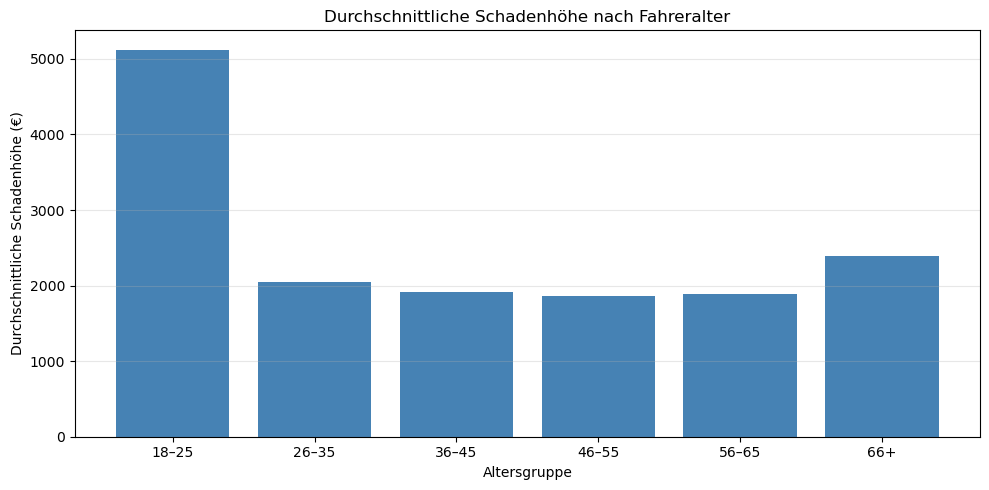

In [120]:

# Altersgruppen definieren
altersgrenzen = [17, 25, 35, 45, 55, 65, float("inf")]
alterslabels = ["18–25", "26–35", "36–45",
                "46–55", "56–65", "66+"]

# Fahrer den Altersgruppen zuordnen
schaden_segment["Altersgruppe"] = pd.cut(
    schaden_segment["DrivAge"],
    bins=altersgrenzen,
    labels=alterslabels
)

# Schadenhöhe nach Altersgruppe berechnen
schadenhoehe_nach_alter = schaden_segment.groupby(
    "Altersgruppe", observed=True
).agg(
    Anzahl_Schadenbetraege=("ClaimAmount", "count"),
    Durchschnitt=("ClaimAmount", "mean"),
    Median=("ClaimAmount", "median"),
    Gesamtkosten=("ClaimAmount", "sum")
)

# Ergebnisse anzeigen
display(schadenhoehe_nach_alter.round(2))

# Durchschnittliche Schadenhöhe visualisieren
plt.figure(figsize=(10, 5))

plt.bar(
    schadenhoehe_nach_alter.index.astype(str),
    schadenhoehe_nach_alter["Durchschnitt"],
    color="steelblue"
)

plt.title("Durchschnittliche Schadenhöhe nach Fahreralter")
plt.xlabel("Altersgruppe")
plt.ylabel("Durchschnittliche Schadenhöhe (€)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation:**

Die Analyse zeigt deutliche Unterschiede in der durchschnittlichen Schadenhöhe zwischen den Altersgruppen.

Die Fahrer im Alter von **18 bis 25 Jahren** weisen mit rund **5.122 €** die höchste durchschnittliche Schadenhöhe auf.

Die niedrigste durchschnittliche Schadenhöhe wurde bei den **46- bis 55-Jährigen** mit rund **1.861 €** festgestellt.

Bei Fahrern ab 66 Jahren steigt der Durchschnitt wieder auf rund **2.397 €**.

Aus versicherungswirtschaftlicher Sicht deutet dies darauf hin, dass jüngere Fahrer im untersuchten Portfolio nicht nur eine höhere Schadenhäufigkeit, sondern auch höhere durchschnittliche Schadenkosten aufweisen.

Allerdings können einzelne besonders hohe Schäden die Durchschnittswerte beeinflussen. Deshalb sollten zusätzlich die Mediane sowie weitere Risikofaktoren berücksichtigt werden.

Die Ergebnisse beziehen sich ausschließlich auf die erfolgreich verknüpften Schadenbeträge und erlauben keine kausalen Schlussfolgerungen.



#### Schadenhöhe nach Bonus-Malus

In diesem Schritt wird untersucht, wie sich die Schadenhöhe zwischen verschiedenen Bonus-Malus-Gruppen unterscheidet.

Ziel ist es, mögliche Zusammenhänge zwischen dem Bonus-Malus-Wert und der finanziellen Höhe einzelner Schäden zu erkennen.

Dazu werden die durchschnittliche und die mediane Schadenhöhe sowie die Anzahl der erfassten Schadenbeträge je Bonus-Malus-Gruppe berechnet.


,Anzahl_Schadenbetraege,Durchschnitt,Median,Gesamtkosten
BonusMalusGruppe,,,,
50,11592,1922.22,1172.00,22282394.02
51–75,7832,1997.27,1162.46,15642614.88
76–100,5764,3369.93,1172.00,19424278.04
101–125,1093,1844.08,1172.00,2015577.77
126–150,109,3776.84,1172.00,411675.38
151+,54,2456.97,1172.00,132676.41


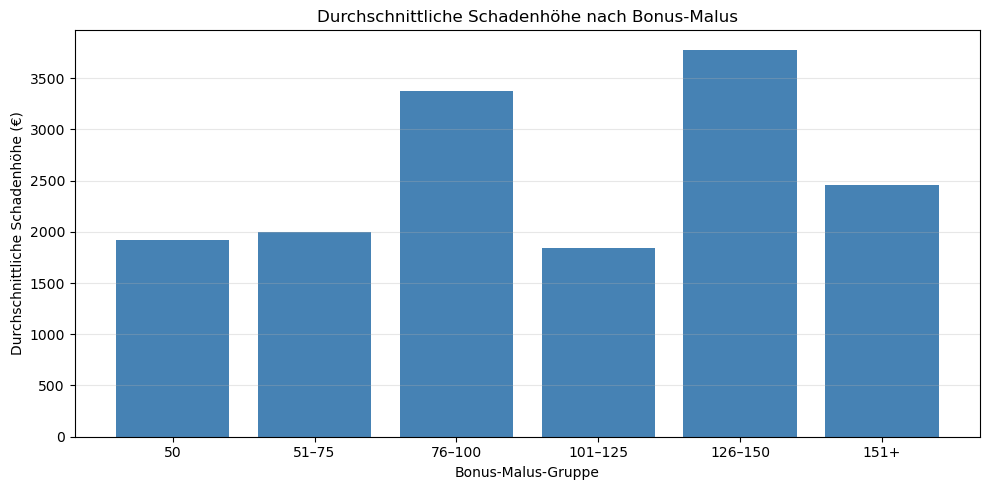

In [124]:

# Bonus-Malus-Gruppen definieren
bonus_grenzen = [49, 50, 75, 100, 125, 150, float("inf")]
bonus_labels = [
    "50", "51–75", "76–100",
    "101–125", "126–150", "151+"
]

# Schadenbeträge den Bonus-Malus-Gruppen zuordnen
schaden_segment["BonusMalusGruppe"] = pd.cut(
    schaden_segment["BonusMalus"],
    bins=bonus_grenzen,
    labels=bonus_labels
)

# Schadenhöhe je Bonus-Malus-Gruppe berechnen
schadenhoehe_nach_bonus = schaden_segment.groupby(
    "BonusMalusGruppe", observed=True
).agg(
    Anzahl_Schadenbetraege=("ClaimAmount", "count"),
    Durchschnitt=("ClaimAmount", "mean"),
    Median=("ClaimAmount", "median"),
    Gesamtkosten=("ClaimAmount", "sum")
)

# Ergebnisse anzeigen
display(schadenhoehe_nach_bonus.round(2))

# Durchschnittliche Schadenhöhe visualisieren
plt.figure(figsize=(10, 5))

plt.bar(
    schadenhoehe_nach_bonus.index.astype(str),
    schadenhoehe_nach_bonus["Durchschnitt"],
    color="steelblue"
)

plt.title("Durchschnittliche Schadenhöhe nach Bonus-Malus")
plt.xlabel("Bonus-Malus-Gruppe")
plt.ylabel("Durchschnittliche Schadenhöhe (€)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation:**

Die Analyse zeigt Unterschiede in der durchschnittlichen Schadenhöhe zwischen den Bonus-Malus-Gruppen.

Die Gruppe mit einem Bonus-Malus-Wert von **126 bis 150** weist mit rund **3.777 €** die höchste durchschnittliche Schadenhöhe auf, gefolgt von der Gruppe **76 bis 100** mit rund **3.370 €**.

Im Gegensatz zur Schadenhäufigkeit ist bei der durchschnittlichen Schadenhöhe jedoch **kein kontinuierlicher Anstieg mit zunehmendem Bonus-Malus-Wert** erkennbar.

Die mediane Schadenhöhe liegt in fast allen Gruppen bei ungefähr **1.172 €**. Dies deutet darauf hin, dass die Unterschiede zwischen den Mittelwerten teilweise durch besonders hohe Einzelschäden beeinflusst werden.

Besonders die Gruppen mit hohen Bonus-Malus-Werten enthalten nur wenige erfasste Schadenbeträge. Ihre Durchschnittswerte sollten daher vorsichtig interpretiert werden.

Aus versicherungswirtschaftlicher Sicht zeigt die Analyse, dass Schadenhäufigkeit und Schadenhöhe getrennt betrachtet werden müssen, da ein erhöhtes Schadenaufkommen nicht automatisch mit höheren durchschnittlichen Schadenkosten verbunden ist.



#### Schadenhöhe nach Region

In diesem Schritt wird untersucht, wie sich die Schadenhöhe zwischen den verschiedenen Regionen unterscheidet.

Ziel ist es, regionale Unterschiede in den durchschnittlichen und medianen Schadenkosten zu erkennen und mögliche geografische Risikosegmente zu identifizieren.

Die Analyse basiert auf den erfolgreich verknüpften Schadenbeträgen aus `schaden_segment`. Neben der durchschnittlichen Schadenhöhe werden auch die Anzahl der erfassten Schäden und die gesamten Schadenkosten je Region betrachtet.


In [128]:

# Schadenhöhe nach Region berechnen
schadenhoehe_nach_region = schaden_segment.groupby("Region").agg(
    Anzahl_Schadenbetraege=("ClaimAmount", "count"),
    Durchschnitt=("ClaimAmount", "mean"),
    Median=("ClaimAmount", "median"),
    Gesamtkosten=("ClaimAmount", "sum")
)

# Regionen nach durchschnittlicher Schadenhöhe sortieren
schadenhoehe_nach_region = schadenhoehe_nach_region.sort_values(
    "Durchschnitt", ascending=False
)

# Ergebnisse anzeigen
display(schadenhoehe_nach_region.round(2))


,Anzahl_Schadenbetraege,Durchschnitt,Median,Gesamtkosten
Region,,,,
Champagne-Ardenne,77,6249.98,1204.00,481248.34
Corse,132,3519.56,1204.00,464582.55
Centre,6475,2945.92,1128.12,19074802.36
Rhone-Alpes,4233,2428.14,1172.00,10278303.85
Provence-Alpes-Cotes-D'Azur,2986,2301.08,1172.00,6871024.80
Picardie,314,2189.89,1172.00,687624.87
Bretagne,1871,2085.01,1147.46,3901051.25
Basse-Normandie,452,2057.18,1128.12,929847.31
Franche-Comte,38,2014.06,1204.00,76534.11



#### Visualisierung: Durchschnittliche Schadenhöhe nach Region

Um die regionalen Unterschiede besser vergleichen zu können, wird die durchschnittliche Schadenhöhe in einem horizontalen Balkendiagramm dargestellt.

Die Regionen werden nach der Höhe des durchschnittlichen Schadenbetrags sortiert.

Da einzelne sehr hohe Schäden den Mittelwert beeinflussen können, müssen die Ergebnisse gemeinsam mit den Medianwerten und der Anzahl der erfassten Schäden interpretiert werden.


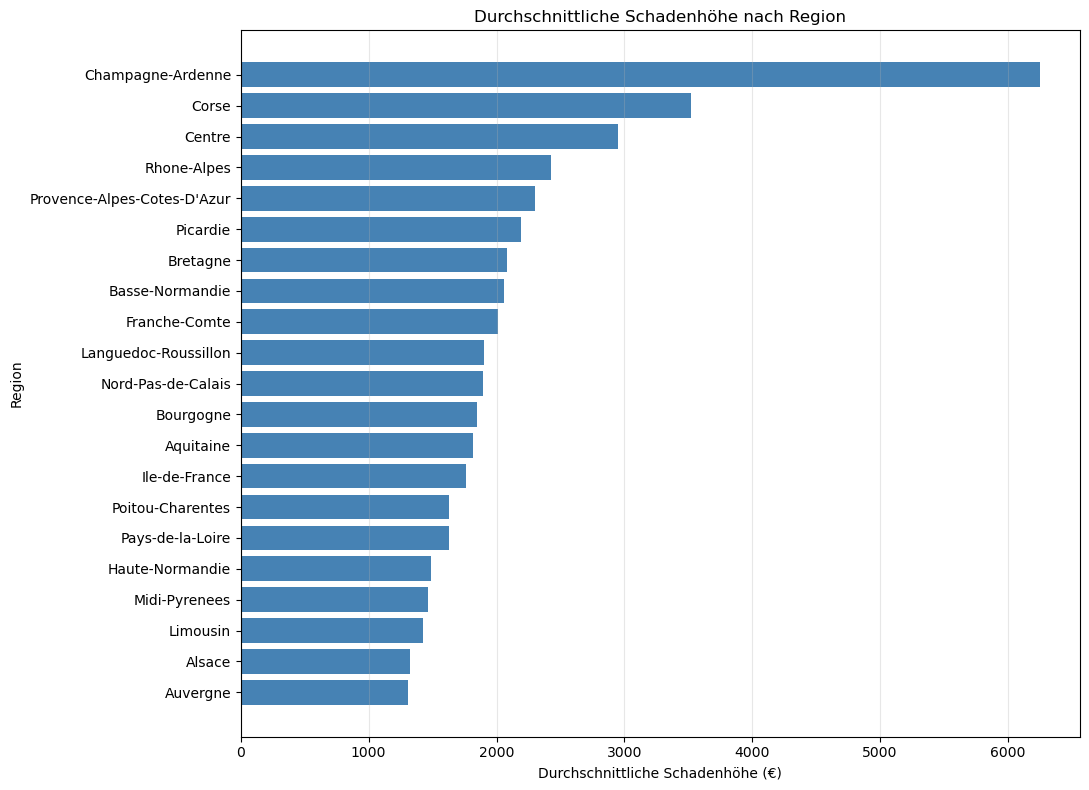

In [131]:

# Durchschnittliche Schadenhöhe nach Region visualisieren
plt.figure(figsize=(11, 8))

plt.barh(
    schadenhoehe_nach_region.index,
    schadenhoehe_nach_region["Durchschnitt"],
    color="steelblue"
)

plt.title("Durchschnittliche Schadenhöhe nach Region")
plt.xlabel("Durchschnittliche Schadenhöhe (€)")
plt.ylabel("Region")

# Region mit dem höchsten Durchschnitt oben anzeigen
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation:**

Die Analyse zeigt deutliche regionale Unterschiede in der durchschnittlichen Schadenhöhe.

Die höchste durchschnittliche Schadenhöhe weist **Champagne-Ardenne** mit rund **6.250 €** auf, gefolgt von **Corse** mit rund **3.520 €** und **Centre** mit rund **2.946 €**.

Allerdings wurden in Champagne-Ardenne nur **77 Schadenbeträge** erfasst. Der Median liegt dort bei lediglich **1.204 €**. Dies deutet darauf hin, dass einzelne hohe Schäden den Durchschnitt stark beeinflussen.

In **Centre** wurden dagegen **6.475 Schadenbeträge** mit gesamten Schadenkosten von rund **19,07 Millionen Euro** erfasst.

Aus versicherungswirtschaftlicher Sicht zeigt die Analyse, dass regionale Risiken nicht allein anhand der durchschnittlichen Schadenhöhe bewertet werden sollten. Auch der Median, die Anzahl der Schäden und die gesamten Schadenkosten sind wichtige Kennzahlen.

Die Ergebnisse beschreiben regionale Unterschiede, erlauben jedoch keine kausalen Schlussfolgerungen.



### 3.7 — Zusammenführung von Schadenhäufigkeit und Schadenhöhe

In diesem Abschnitt werden die bisherigen Analysen zur Schadenhäufigkeit und Schadenhöhe miteinander verbunden.

Ziel ist es, die finanziellen Auswirkungen der gemeldeten Schäden im Verhältnis zur Exposition des Versicherungsportfolios zu untersuchen.

Dazu wird der beobachtete Schadenaufwand pro Versicherungsjahr berechnet. Dieser Indikator ermöglicht einen Vergleich der finanziellen Schadenbelastung zwischen verschiedenen Risikosegmenten.

Da nicht für alle im Häufigkeitsdatensatz gezählten Schäden ein entsprechender Schadenbetrag vorliegt, werden die Ergebnisse als beobachtete und nicht als vollständige Schadenkosten interpretiert.


In [135]:

# Schadenbeträge je Versicherungsvertrag zusammenfassen
kosten_pro_vertrag = schaden_segment.groupby("IDpol").agg(
    Schadenkosten=("ClaimAmount", "sum")
).reset_index()

# Schadenkosten mit allen Versicherungsverträgen verknüpfen
portfolio_kosten = freq.merge(
    kosten_pro_vertrag,
    on="IDpol",
    how="left",
    validate="one_to_one"
)

# Verträge ohne zugeordneten Schadenbetrag erhalten beobachtete Kosten von 0
portfolio_kosten["Schadenkosten"] = (
    portfolio_kosten["Schadenkosten"].fillna(0)
)

# Gesamte beobachtete Schadenkosten berechnen
beobachtete_schadenkosten = portfolio_kosten["Schadenkosten"].sum()

# Gesamte Exposition berechnen
gesamte_exposition = portfolio_kosten["Exposure"].sum()

# Beobachteten Schadenaufwand pro Versicherungsjahr berechnen
schadenaufwand_pro_jahr = (
    beobachtete_schadenkosten / gesamte_exposition
)

# Ergebnisse ausgeben
print(f"Beobachtete Schadenkosten: {beobachtete_schadenkosten:,.2f} €")
print(f"Gesamte Exposition: {gesamte_exposition:,.2f}")
print(f"Schadenaufwand pro Versicherungsjahr: {schadenaufwand_pro_jahr:,.2f} €")


Beobachtete Schadenkosten: 59,909,216.50 €
Gesamte Exposition: 358,499.45
Schadenaufwand pro Versicherungsjahr: 167.11 €



**Interpretation:**

Die erfolgreich zugeordneten Schadenbeträge ergeben beobachtete Schadenkosten von insgesamt rund **59,91 Millionen Euro**.

Bei einer gesamten Exposition von rund **358.499 Versicherungsjahren** entspricht dies einem beobachteten Schadenaufwand von **167,11 € pro Versicherungsjahr**.

Dieser Wert beschreibt die finanzielle Schadenbelastung des untersuchten Portfolios auf Grundlage der verfügbaren und zugeordneten Schadenbeträge.

Da nicht alle gemeldeten Schäden mit einem Schadenbetrag verknüpft werden können, stellt dieser Indikator keine vollständige Schätzung der tatsächlichen Schadenkosten dar.

Aus versicherungswirtschaftlicher Sicht bietet er dennoch eine Grundlage, um die beobachtete finanzielle Schadenbelastung zwischen verschiedenen Risikosegmenten zu vergleichen.



#### 3.7.1 — Beobachteter Schadenaufwand nach Fahreralter

In diesem Schritt wird untersucht, wie sich der beobachtete Schadenaufwand pro Versicherungsjahr zwischen verschiedenen Altersgruppen der Fahrer unterscheidet.

Ziel ist es, die finanzielle Schadenbelastung der einzelnen Altersgruppen unter Berücksichtigung der Exposition zu vergleichen.

Dazu werden die zugeordneten Schadenkosten durch die gesamte Exposition der jeweiligen Altersgruppe geteilt. Auf diese Weise werden sowohl die Häufigkeit als auch die Höhe der erfassten Schäden berücksichtigt.


In [139]:

# Altersgruppen definieren
altersgrenzen = [17, 25, 35, 45, 55, 65, float("inf")]
alterslabels = [
    "18–25", "26–35", "36–45",
    "46–55", "56–65", "66+"
]

# Fahrer den Altersgruppen zuordnen
portfolio_kosten["Altersgruppe"] = pd.cut(
    portfolio_kosten["DrivAge"],
    bins=altersgrenzen,
    labels=alterslabels
)

# Schadenkosten und Exposition nach Altersgruppe aggregieren
schadenaufwand_nach_alter = portfolio_kosten.groupby(
    "Altersgruppe", observed=True
).agg(
    Anzahl_Vertraege=("IDpol", "count"),
    Anzahl_Schaeden=("ClaimNb", "sum"),
    Exposition=("Exposure", "sum"),
    Schadenkosten=("Schadenkosten", "sum")
)

# Jährliche Schadenhäufigkeit berechnen
schadenaufwand_nach_alter["Schadenhaeufigkeit"] = (
    schadenaufwand_nach_alter["Anzahl_Schaeden"]
    / schadenaufwand_nach_alter["Exposition"]
)

# Beobachteten Schadenaufwand pro Versicherungsjahr berechnen
schadenaufwand_nach_alter["Schadenaufwand_pro_Jahr"] = (
    schadenaufwand_nach_alter["Schadenkosten"]
    / schadenaufwand_nach_alter["Exposition"]
)

# Ergebnisse anzeigen
display(schadenaufwand_nach_alter.round(2))


,Anzahl_Vertraege,Anzahl_Schaeden,Exposition,Schadenkosten,Schadenhaeufigkeit,Schadenaufwand_pro_Jahr
Altersgruppe,,,,,,
18–25,38895,2841,16227.90,12307261.54,0.18,758.40
26–35,149183,6662,69266.78,10607248.80,0.10,153.14
36–45,170352,8397,87702.34,12119011.84,0.10,138.18
46–55,161899,9256,89268.78,12326494.29,0.10,138.08
56–65,90691,4748,51775.55,6267615.63,0.09,121.05
66+,66993,4198,44258.10,6281584.40,0.09,141.93



#### Visualisierung: Beobachteter Schadenaufwand nach Fahreralter

Um die finanzielle Schadenbelastung der verschiedenen Altersgruppen besser vergleichen zu können, wird der beobachtete Schadenaufwand pro Versicherungsjahr in einem Balkendiagramm dargestellt.

Ziel ist es, Altersgruppen mit besonders hohen Schadenkosten im Verhältnis zu ihrer Exposition zu identifizieren.


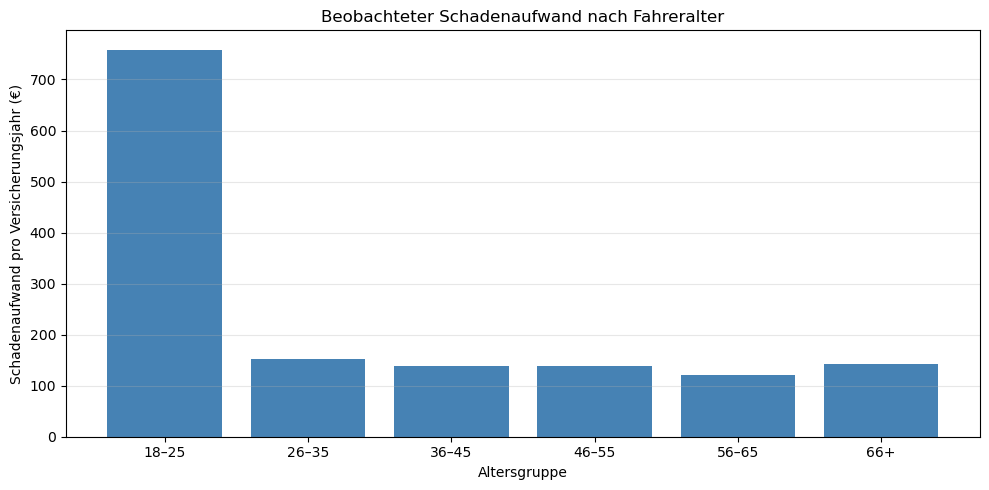

In [142]:

# Beobachteten Schadenaufwand nach Altersgruppe visualisieren
plt.figure(figsize=(10, 5))

plt.bar(
    schadenaufwand_nach_alter.index.astype(str),
    schadenaufwand_nach_alter["Schadenaufwand_pro_Jahr"],
    color="steelblue"
)

plt.title("Beobachteter Schadenaufwand nach Fahreralter")
plt.xlabel("Altersgruppe")
plt.ylabel("Schadenaufwand pro Versicherungsjahr (€)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation:**

Die Analyse zeigt deutliche Unterschiede im beobachteten Schadenaufwand pro Versicherungsjahr zwischen den Altersgruppen.

Die Fahrer im Alter von **18 bis 25 Jahren** weisen mit **758,40 € pro Versicherungsjahr** die höchste finanzielle Schadenbelastung auf.

Dieser Wert liegt deutlich über den Ergebnissen der übrigen Altersgruppen, deren beobachteter Schadenaufwand zwischen **121,05 € und 153,14 €** beträgt.

Die niedrigste finanzielle Schadenbelastung wurde bei den **56- bis 65-Jährigen** mit **121,05 € pro Versicherungsjahr** festgestellt.

Die jüngste Altersgruppe weist sowohl eine höhere Schadenhäufigkeit als auch höhere durchschnittliche Schadenbeträge auf. Zudem können einzelne besonders hohe Schäden den beobachteten Schadenaufwand stark beeinflussen.

Aus versicherungswirtschaftlicher Sicht deutet dies auf ein erhöhtes finanzielles Risiko in der jüngsten Altersgruppe hin.

Da die verfügbaren Schadenbeträge nicht alle gemeldeten Schäden abdecken, beschreiben die Ergebnisse ausschließlich den beobachteten Schadenaufwand. Weitere Risikofaktoren müssen berücksichtigt werden, bevor daraus Schlussfolgerungen für die Tarifgestaltung gezogen werden können.



#### 3.7.2 — Vergleich der finanziellen Schadenbelastung nach Risikofaktoren

Nachdem Schadenhäufigkeit und Schadenhöhe getrennt analysiert wurden, werden die beobachteten Schadenkosten nun für mehrere Risikofaktoren gemeinsam betrachtet.

Ziel ist es, Unterschiede im beobachteten Schadenaufwand pro Versicherungsjahr nach Fahreralter, Bonus-Malus und Fahrzeugalter übersichtlich darzustellen.

Die Ergebnisse ermöglichen eine vergleichende Risikosegmentierung. Da die verfügbaren Schadenbeträge nicht alle gemeldeten Schäden abdecken, handelt es sich um eine deskriptive Analyse der beobachteten Schadenbelastung.


In [148]:

# Altersgruppen der Fahrer definieren
portfolio_kosten["Fahreralter_Gruppe"] = pd.cut(
    portfolio_kosten["DrivAge"],
    bins=[17, 25, 35, 45, 55, 65, float("inf")],
    labels=["18–25", "26–35", "36–45", "46–55", "56–65", "66+"]
)

# Bonus-Malus-Gruppen definieren
portfolio_kosten["BonusMalus_Gruppe"] = pd.cut(
    portfolio_kosten["BonusMalus"],
    bins=[49, 50, 75, 100, 125, 150, float("inf")],
    labels=["50", "51–75", "76–100", "101–125", "126–150", "151+"]
)

# Fahrzeugaltersgruppen definieren
portfolio_kosten["Fahrzeugalter_Gruppe"] = pd.cut(
    portfolio_kosten["VehAge"],
    bins=[-1, 2, 5, 10, 15, float("inf")],
    labels=["0–2", "3–5", "6–10", "11–15", "16+"]
)

# Funktion zur Berechnung des beobachteten Schadenaufwands
def berechne_schadenaufwand(daten, gruppenspalte):
    ergebnis = daten.groupby(
        gruppenspalte, observed=True
    ).agg(
        Anzahl_Vertraege=("IDpol", "count"),
        Exposition=("Exposure", "sum"),
        Schadenkosten=("Schadenkosten", "sum")
    )

    ergebnis["Schadenaufwand_pro_Jahr"] = (
        ergebnis["Schadenkosten"] / ergebnis["Exposition"]
    )

    return ergebnis


# Schadenaufwand für drei Risikofaktoren berechnen
risiko_fahreralter = berechne_schadenaufwand(
    portfolio_kosten, "Fahreralter_Gruppe"
)

risiko_bonusmalus = berechne_schadenaufwand(
    portfolio_kosten, "BonusMalus_Gruppe"
)

risiko_fahrzeugalter = berechne_schadenaufwand(
    portfolio_kosten, "Fahrzeugalter_Gruppe"
)

# Ergebnisse kontrollieren
display(risiko_fahreralter.round(2))
display(risiko_bonusmalus.round(2))
display(risiko_fahrzeugalter.round(2))


,Anzahl_Vertraege,Exposition,Schadenkosten,Schadenaufwand_pro_Jahr
Fahreralter_Gruppe,,,,
18–25,38895,16227.90,12307261.54,758.40
26–35,149183,69266.78,10607248.80,153.14
36–45,170352,87702.34,12119011.84,138.18
46–55,161899,89268.78,12326494.29,138.08
56–65,90691,51775.55,6267615.63,121.05
66+,66993,44258.10,6281584.40,141.93


,Anzahl_Vertraege,Exposition,Schadenkosten,Schadenaufwand_pro_Jahr
BonusMalus_Gruppe,,,,
50,384156,225233.13,22282394.02,98.93
51–75,175012,84874.66,15642614.88,184.30
76–100,111051,44820.34,19424278.04,433.38
101–125,6987,3198.27,2015577.77,630.21
126–150,598,277.92,411675.38,1481.25
151+,209,95.13,132676.41,1394.71


,Anzahl_Vertraege,Exposition,Schadenkosten,Schadenaufwand_pro_Jahr
Fahrzeugalter_Gruppe,,,,
0–2,188147,79176.06,12299662.34,155.35
3–5,132490,72040.12,10552899.23,146.49
6–10,171594,99008.92,15805071.87,159.63
11–15,134063,77990.98,17808346.08,228.34
16+,51719,30283.37,3443236.98,113.70



#### Visualisierung: Vergleich der Risikosegmente

Die folgenden drei Diagramme zeigen den beobachteten Schadenaufwand pro Versicherungsjahr nach Fahreralter, Bonus-Malus und Fahrzeugalter.

Durch die gemeinsame Darstellung lassen sich besonders kostenintensive Risikosegmente erkennen.

Die Balkenhöhen beschreiben die beobachteten Schadenkosten im Verhältnis zur Exposition. Die verschiedenen Risikofaktoren werden dabei jeweils einzeln betrachtet.


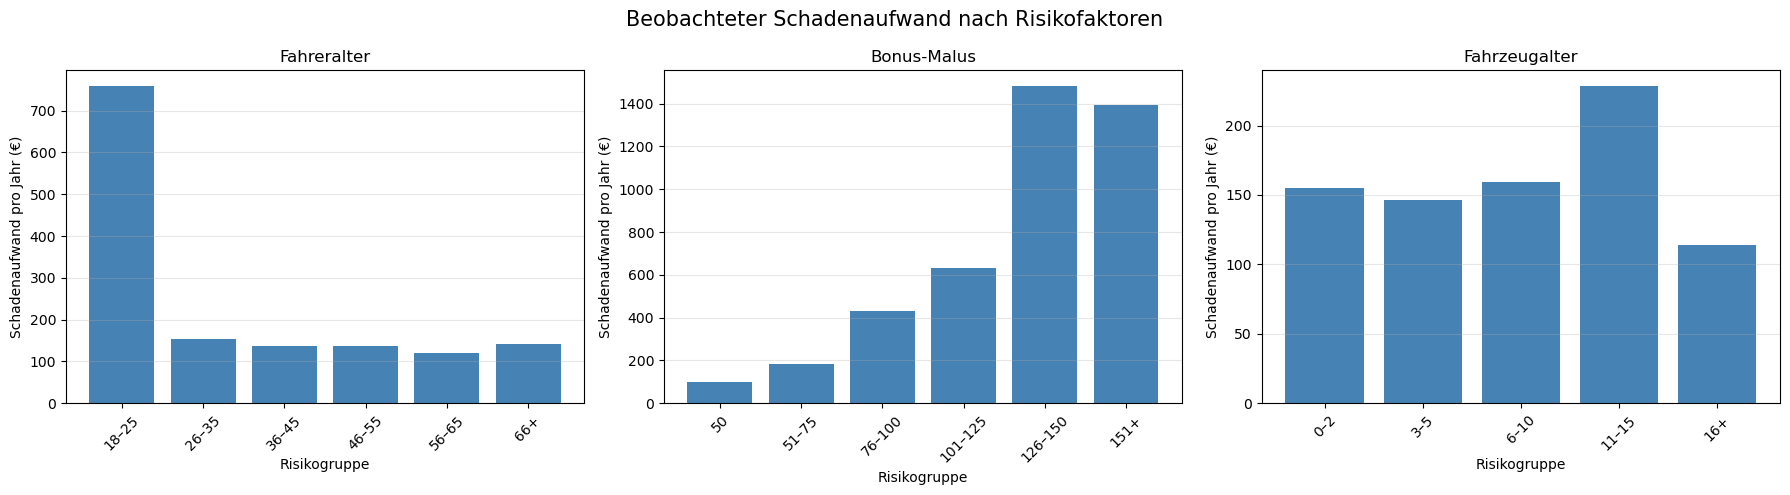

In [151]:

# Drei Risikofaktoren in einer Abbildung vergleichen
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

risikofaktoren = [
    (risiko_fahreralter, "Fahreralter"),
    (risiko_bonusmalus, "Bonus-Malus"),
    (risiko_fahrzeugalter, "Fahrzeugalter")
]

for ax, (daten, titel) in zip(axes, risikofaktoren):
    ax.bar(
        daten.index.astype(str),
        daten["Schadenaufwand_pro_Jahr"],
        color="steelblue"
    )

    ax.set_title(titel)
    ax.set_xlabel("Risikogruppe")
    ax.set_ylabel("Schadenaufwand pro Jahr (€)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Beobachteter Schadenaufwand nach Risikofaktoren",
    fontsize=15
)

plt.tight_layout()
plt.show()



**Interpretation:**

Die vergleichende Analyse zeigt, dass sich die beobachtete finanzielle Schadenbelastung zwischen den untersuchten Risikosegmenten deutlich unterscheidet.

Beim **Fahreralter** weisen die 18- bis 25-Jährigen mit rund **758 € pro Versicherungsjahr** den höchsten beobachteten Schadenaufwand auf.

Beim **Bonus-Malus** ist insgesamt ein deutlicher Anstieg der finanziellen Schadenbelastung in höheren Gruppen erkennbar. Besonders hohe Werte treten in den Gruppen 126–150 und 151+ auf. Da diese Gruppen nur eine geringe Exposition aufweisen, sind ihre Ergebnisse jedoch besonders anfällig für den Einfluss einzelner Großschäden.

Beim **Fahrzeugalter** weisen Fahrzeuge zwischen 11 und 15 Jahren mit rund **228 € pro Versicherungsjahr** die höchste beobachtete Schadenbelastung auf.

Die Ergebnisse zeigen, dass Fahreralter, Bonus-Malus und Fahrzeugalter relevante Merkmale für die deskriptive Risikosegmentierung sind.

Allerdings werden die Faktoren hier einzeln betrachtet. Mögliche Zusammenhänge zwischen den Merkmalen sowie die unvollständige Zuordnung der Schadenbeträge müssen bei der Interpretation berücksichtigt werden.

Für eine weiterführende Bewertung sind multivariate statistische Modelle erforderlich.



### 3.8 Zusammenfassung der wichtigsten Ergebnisse

Die Claims & Risk Analytics haben zentrale Zusammenhänge zwischen den Risikomerkmalen der Versicherungsverträge, der Schadenhäufigkeit und der finanziellen Schadenbelastung aufgezeigt.

**1. Schadenhäufigkeit**

Im untersuchten Versicherungsportfolio wurden insgesamt **36.102 Schäden** bei einer Exposition von rund **358.499 Versicherungsjahren** erfasst. Daraus ergibt sich eine jährliche Schadenhäufigkeit von rund **10,07 %**.

Die Analyse nach Risikosegmenten zeigt, dass insbesondere das Fahreralter und der Bonus-Malus-Wert wichtige Unterschiede in der beobachteten Schadenhäufigkeit aufweisen.

**2. Schadenhöhe**

Die durchschnittliche Schadenhöhe beträgt rund **2.279 €**, während der Median bei **1.172 €** liegt.

Der deutliche Unterschied zwischen Mittelwert und Median weist auf eine rechtsschiefe Verteilung hin, bei der einzelne sehr hohe Schäden den Durchschnitt beeinflussen.

**3. Großschäden (Large Loss Analysis)**

Die Analyse der größten Schäden zeigt eine starke Konzentration der Schadenkosten: Die teuersten **1 % der erfassten Schäden** verursachen rund **38 % der gesamten Schadenkosten**.

Dies verdeutlicht die Bedeutung von Großschäden für die finanzielle Risikobewertung.

**4. Finanzielle Schadenbelastung**

Durch die Verknüpfung der Schadenbeträge mit den Versicherungsverträgen wurde ein beobachteter Schadenaufwand von rund **167 € pro Versicherungsjahr** ermittelt.

Besonders die Altersgruppe der **18- bis 25-jährigen Fahrer** weist eine erhöhte beobachtete finanzielle Schadenbelastung auf.

Auch bei höheren Bonus-Malus-Werten zeigen sich teilweise deutlich erhöhte Schadenkosten im Verhältnis zur Exposition.

**Gesamtfazit**

Die Ergebnisse verdeutlichen, dass eine umfassende Risikobewertung sowohl die Schadenhäufigkeit als auch die Schadenhöhe berücksichtigen muss.

Die Kombination beider Perspektiven ermöglicht eine differenziertere Betrachtung der finanziellen Schadenbelastung einzelner Risikosegmente.

Die Erkenntnisse bilden eine Grundlage für weiterführende SQL-Analysen und statistische Risikomodelle.



### 3.9 Datenlimitationen und Ausblick

#### Datenlimitationen

Bei der Interpretation der Ergebnisse müssen mehrere Einschränkungen der verwendeten Datensätze berücksichtigt werden.

**1. Unvollständige Verknüpfung der Datensätze**

Der Datensatz zur Schadenhäufigkeit enthält insgesamt **36.102 gemeldete Schäden**, während im Datensatz zur Schadenhöhe **26.639 Schadenbeträge** erfasst sind.

Davon konnten **26.444 Schadenbeträge** erfolgreich mit den Versicherungsverträgen verknüpft werden. Für **195 Schadenbeträge** wurde kein entsprechender Vertrag im Häufigkeitsdatensatz gefunden.

Die berechneten finanziellen Kennzahlen basieren daher auf den verfügbaren und erfolgreich zugeordneten Schadenbeträgen. Sie bilden nicht zwangsläufig die vollständige Schadenbelastung des Portfolios ab.

**2. Einfluss extremer Schadenbeträge**

Die Schadenhöhen weisen eine stark rechtsschiefe Verteilung auf. Einzelne Großschäden können die durchschnittliche Schadenhöhe und den beobachteten Schadenaufwand erheblich beeinflussen.

Aus diesem Grund wurden neben den Mittelwerten auch Medianwerte und die Verteilung der Schadenbeträge untersucht.

**3. Unterschiedliche Gruppengrößen**

Einige Risikosegmente enthalten deutlich weniger Verträge beziehungsweise Schadenbeträge als andere.

Insbesondere Ergebnisse kleiner Gruppen können stark durch einzelne Beobachtungen beeinflusst werden und sollten deshalb vorsichtig interpretiert werden.

**4. Deskriptive Analyse**

Die bisherigen Untersuchungen beschreiben statistische Zusammenhänge, erlauben jedoch keine kausalen Schlussfolgerungen.

Da Risikomerkmale miteinander zusammenhängen können, ist eine isolierte Betrachtung einzelner Variablen für eine vollständige Risikobewertung nicht ausreichend.

**5. Fehlende Prämieninformationen**

Die verwendeten Datensätze enthalten keine Versicherungsprämien. Daher kann keine Schadenquote (*Loss Ratio*) berechnet werden.

#### Ausblick

Aufbauend auf den bisherigen Ergebnissen sind folgende Erweiterungen vorgesehen:

- **SQL & PostgreSQL:** Speicherung der Versicherungsdaten in einer relationalen Datenbank und Berechnung zentraler Kennzahlen mithilfe von SQL-Abfragen.
- **Statistische Risikomodellierung:** Untersuchung der Schadenhäufigkeit und ihrer Einflussfaktoren mithilfe geeigneter statistischer Modelle, beispielsweise der Poisson-Regression.
- **Portfolio-Dokumentation:** Zusammenfassung der Methodik, Ergebnisse und Einschränkungen in einer nachvollziehbaren GitHub-Dokumentation.

Die bisherigen Analysen schaffen damit eine Grundlage für eine weiterführende datenbasierte Untersuchung des Versicherungsrisikos.


## 5. Statistische Risikomodellierung ##



### 5.1 — Vorbereitung der Poisson-Regression

In diesem Abschnitt wird untersucht, wie verschiedene Risikofaktoren mit der Anzahl der gemeldeten Versicherungsschäden zusammenhängen.

Dazu wird eine Poisson-Regression verwendet. Die Exposition wird berücksichtigt, um unterschiedliche Beobachtungsdauern der Versicherungsverträge einzubeziehen.

Zunächst werden die Modellvariablen ausgewählt und auf fehlende Werte sowie ungültige Expositionswerte überprüft.

In [160]:

# Datensatz für die Modellierung vorbereiten
model_df = freq.copy()

# Relevante Variablen auswählen
modellvariablen = [
    "ClaimNb",
    "Exposure",
    "DrivAge",
    "VehAge",
    "VehPower",
    "BonusMalus",
    "VehGas",
    "Area"
]

model_df = model_df[modellvariablen].copy()

# Datenqualität vor der Modellierung prüfen
print("Anzahl der Beobachtungen:", len(model_df))

print("\nFehlende Werte:")
print(model_df.isna().sum())

print("\nVerträge mit ungültiger Exposition:")
print((model_df["Exposure"] <= 0).sum())

display(model_df.head())


Anzahl der Beobachtungen: 678013

Fehlende Werte:
ClaimNb       0
Exposure      0
DrivAge       0
VehAge        0
VehPower      0
BonusMalus    0
VehGas        0
Area          0
dtype: int64

Verträge mit ungültiger Exposition:
0


,ClaimNb,Exposure,DrivAge,VehAge,VehPower,BonusMalus,VehGas,Area
0,1,0.10,55,0,5,50,Regular,D
1,1,0.77,55,0,5,50,Regular,D
2,1,0.75,52,2,6,50,Diesel,B
3,1,0.09,46,0,7,50,Diesel,B
4,1,0.84,46,0,7,50,Diesel,B


#### **Interpretation der Datenvorbereitung**

Der Modelldatensatz umfasst insgesamt **678.013 Versicherungsverträge**. Für die ausgewählten Modellvariablen wurden keine fehlenden Werte festgestellt. Zudem weisen alle Verträge eine positive Exposition auf.

Damit sind die grundlegenden Voraussetzungen für die weitere Modellierung erfüllt. Es ist kein Ausschluss von Beobachtungen aufgrund fehlender Werte oder ungültiger Expositionen erforderlich.

### 5.2 — Poisson-Regression zur Modellierung der Schadenhäufigkeit

Die Poisson-Regression wird verwendet, um den Zusammenhang zwischen ausgewählten Risikofaktoren und der erwarteten Anzahl der Versicherungsschäden zu untersuchen.

Die Exposition wird als logarithmischer Offset in das Modell aufgenommen. Dadurch wird die unterschiedliche Beobachtungsdauer der Versicherungsverträge berücksichtigt.

In [165]:

import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Poisson-Modell mit logarithmischem Expositions-Offset
poisson_model = smf.glm(
    formula=(
        "ClaimNb ~ DrivAge + VehAge + VehPower "
        "+ BonusMalus + C(VehGas) + C(Area)"
    ),
    data=model_df,
    family=sm.families.Poisson(),
    offset=np.log(model_df["Exposure"])
).fit()

# Modellergebnisse anzeigen
print(poisson_model.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   678002
Model Family:                 Poisson   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.4345e+05
Date:                Fri, 06 Nov 2026   Deviance:                   2.1758e+05
Time:                        16:25:48   Pearson chi2:                 1.82e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01012
Covariance Type:            nonrobust                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -3.9305 

**Interpretation der Poisson-Regression**

Die Poisson-Regression wurde auf **678.013 Versicherungsverträge** angewendet. Die Exposition wurde als logarithmischer Offset berücksichtigt.

Die Ergebnisse zeigen statistisch signifikante Zusammenhänge zwischen der erwarteten Schadenanzahl und den untersuchten Risikofaktoren.

- **BonusMalus:** Ein höherer Bonus-Malus-Wert ist mit einer höheren erwarteten Schadenhäufigkeit verbunden.
- **VehPower:** Eine höhere Fahrzeugleistung weist ebenfalls einen positiven Zusammenhang mit der erwarteten Schadenhäufigkeit auf.
- **VehAge:** Das Fahrzeugalter zeigt im Modell einen negativen Zusammenhang.
- **DrivAge:** Das Fahreralter weist bei linearer Modellierung einen positiven Koeffizienten auf. Dieser Befund sollte vorsichtig interpretiert werden, da die deskriptive Analyse auf Unterschiede zwischen Altersgruppen hinweist.
- **VehGas:** Fahrzeuge mit Benzinantrieb weisen unter Berücksichtigung der übrigen Modellvariablen eine höhere erwartete Schadenhäufigkeit auf als Dieselfahrzeuge.

Die Koeffizienten beschreiben statistische Zusammenhänge und erlauben keine unmittelbaren kausalen Schlussfolgerungen.

Vor der abschließenden Bewertung muss überprüft werden, ob die Annahmen des Poisson-Modells ausreichend erfüllt sind.

### 5.3 — Überprüfung der Überdispersion

Bei der Poisson-Regression wird angenommen, dass die bedingte Varianz der Schadenanzahl ihrem bedingten Erwartungswert entspricht.

Zur Überprüfung dieser Annahme wird das Verhältnis der Pearson-Chi-Quadrat-Statistik zu den residualen Freiheitsgraden berechnet. Ein deutlich über 1 liegender Wert kann auf Überdispersion hinweisen.

In [169]:

# Überdispersion des Poisson-Modells überprüfen
dispersion = poisson_model.pearson_chi2 / poisson_model.df_resid

print(f"Pearson-Chi-Quadrat: {poisson_model.pearson_chi2:.2f}")
print(f"Residuale Freiheitsgrade: {poisson_model.df_resid}")
print(f"Dispersionsparameter: {dispersion:.2f}")


Pearson-Chi-Quadrat: 1823331.95
Residuale Freiheitsgrade: 678002
Dispersionsparameter: 2.69


**Interpretation der Überdispersion**

Der berechnete Dispersionsparameter beträgt **2,69** und liegt damit deutlich über dem Referenzwert von 1.

Dieses Ergebnis weist auf eine Überdispersion im Poisson-Modell hin. Die beobachtete Streuung der Schadenanzahl wird durch das Modell nicht ausreichend abgebildet.

Dadurch können die Standardfehler und Signifikanztests des klassischen Poisson-Modells verzerrt sein.

Als nächster Schritt wird ein Modell mit angepasster Varianzannahme betrachtet.

### 5.4 — Anpassung des Poisson-Modells bei Überdispersion

Aufgrund der festgestellten Überdispersion wird ein Poisson-Modell mit angepasstem Skalierungsparameter geschätzt.

Die Regressionskoeffizienten bleiben unverändert, während die Standardfehler und Signifikanztests an die erhöhte Streuung angepasst werden.

Dieses Vorgehen entspricht einer Quasi-Poisson-ähnlichen Varianzkorrektur.

In [173]:

# Poisson-Modell mit angepasstem Dispersionsparameter
quasi_poisson_model = smf.glm(
    formula=(
        "ClaimNb ~ DrivAge + VehAge + VehPower "
        "+ BonusMalus + C(VehGas) + C(Area)"
    ),
    data=model_df,
    family=sm.families.Poisson(),
    offset=np.log(model_df["Exposure"])
).fit(scale="X2")

# Angepasste Modellergebnisse anzeigen
print(quasi_poisson_model.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   678002
Model Family:                 Poisson   Df Model:                           10
Link Function:                    Log   Scale:                          2.6893
Method:                          IRLS   Log-Likelihood:                -53343.
Date:                Fri, 06 Nov 2026   Deviance:                   2.1758e+05
Time:                        16:31:03   Pearson chi2:                 1.82e+06
No. Iterations:                     9   Pseudo R-squ. (CS):           0.003777
Covariance Type:            nonrobust                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -3.9305 

**Interpretation des angepassten Poisson-Modells**

Das angepasste Poisson-Modell weist einen geschätzten Dispersionsparameter von **2,6893** auf.

Die Regressionskoeffizienten bleiben gegenüber dem ursprünglichen Poisson-Modell unverändert. Durch die Berücksichtigung der Überdispersion erhöhen sich jedoch die geschätzten Standardfehler.

Besonders deutlich wird dies bei der Gebietskategorie **Area B**: Während der Zusammenhang im ursprünglichen Modell bei einem Signifikanzniveau von 5 % statistisch signifikant war (p = 0,042), ist er nach der Anpassung nicht mehr signifikant (p = 0,215).

Die übrigen untersuchten Risikofaktoren zeigen überwiegend weiterhin statistisch signifikante Zusammenhänge mit der erwarteten Schadenhäufigkeit.

Die Varianzkorrektur verbessert die statistische Inferenz, behebt jedoch nicht automatisch mögliche Einschränkungen der Modellstruktur.

### 5.5 — Vergleich der Modellkoeffizienten

Zur besseren Vergleichbarkeit werden die geschätzten Koeffizienten, Standardfehler und p-Werte des klassischen Poisson-Modells und des angepassten Modells gegenübergestellt.

In [177]:

import pandas as pd

# Modellkoeffizienten und Signifikanzwerte vergleichen
modellvergleich = pd.DataFrame({
    "Variable": poisson_model.params.index,
    "Poisson_Koeffizient": poisson_model.params.values,
    "Quasi_Poisson_Koeffizient": quasi_poisson_model.params.values,
    "Poisson_Standardfehler": poisson_model.bse.values,
    "Quasi_Poisson_Standardfehler": quasi_poisson_model.bse.values,
    "Poisson_p_Wert": poisson_model.pvalues.values,
    "Quasi_Poisson_p_Wert": quasi_poisson_model.pvalues.values
})

display(modellvergleich.round(4))


,Variable,Poisson_Koeffizient,Quasi_Poisson_Koeffizient,Poisson_Standardfehler,Quasi_Poisson_Standardfehler,Poisson_p_Wert,Quasi_Poisson_p_Wert
0,Intercept,-3.9305,-3.9305,0.0395,0.0648,0.0000,0.0000
1,C(VehGas)[T.Regular],0.0628,0.0628,0.0108,0.0178,0.0000,0.0004
2,C(Area)[T.B],0.0436,0.0436,0.0215,0.0352,0.0422,0.2154
3,C(Area)[T.C],0.0750,0.0750,0.0173,0.0285,0.0000,0.0084
4,C(Area)[T.D],0.1592,0.1592,0.0179,0.0294,0.0000,0.0000
5,C(Area)[T.E],0.2067,0.2067,0.0184,0.0301,0.0000,0.0000
6,C(Area)[T.F],0.1985,0.1985,0.0334,0.0548,0.0000,0.0003
7,DrivAge,0.0067,0.0067,0.0004,0.0006,0.0000,0.0000
8,VehAge,-0.0428,-0.0428,0.0011,0.0017,0.0000,0.0000
9,VehPower,0.0187,0.0187,0.0026,0.0043,0.0000,0.0000


**Interpretation des Modellvergleichs**

Der Vergleich zeigt, dass die geschätzten Regressionskoeffizienten des klassischen Poisson-Modells und des angepassten Modells identisch sind.

Die Standardfehler fallen im angepassten Modell jedoch höher aus. Dies ist auf die Berücksichtigung der zuvor festgestellten Überdispersion zurückzuführen.

Für die Gebietskategorie **Area B** verändert sich dadurch die statistische Bewertung: Der Zusammenhang ist nach der Anpassung auf dem 5-%-Niveau nicht mehr signifikant.

Die Ergebnisse verdeutlichen, dass eine Überprüfung der Modellannahmen für die zuverlässige Interpretation statistischer Zusammenhänge wichtig ist.

### 5.6 — Aufteilung in Trainings- und Testdaten

Zur Bewertung der Vorhersagefähigkeit wird der Datensatz in Trainings- und Testdaten aufgeteilt.

**80 %** der Beobachtungen werden für das Training und **20 %** für die anschließende Bewertung verwendet.

Die Aufteilung erfolgt zufällig und reproduzierbar mit einem festen Zufallswert (`random_state=42`). Die Testdaten werden nicht zur Schätzung der Modellparameter verwendet.

In [181]:

from sklearn.model_selection import train_test_split

# Datensatz in Trainings- und Testdaten aufteilen
train_df, test_df = train_test_split(
    model_df,
    test_size=0.20,
    random_state=42
)

# Größe der Datensätze überprüfen
print("Trainingsdaten:", len(train_df))
print("Testdaten:", len(test_df))

print("\nAnteil der Trainingsdaten:",
      round(len(train_df) / len(model_df) * 100, 2), "%")

print("Anteil der Testdaten:",
      round(len(test_df) / len(model_df) * 100, 2), "%")


Trainingsdaten: 542410
Testdaten: 135603

Anteil der Trainingsdaten: 80.0 %
Anteil der Testdaten: 20.0 %


**Interpretation der Datenaufteilung**

Der Datensatz mit insgesamt **678.013 Versicherungsverträgen** wurde erfolgreich in Trainings- und Testdaten aufgeteilt.

Das Trainingsset umfasst **542.410 Beobachtungen (80 %)**, während das Testset **135.603 Beobachtungen (20 %)** enthält.

Die Aufteilung bildet die Grundlage für eine unabhängige Bewertung der Vorhersagefähigkeit des Modells.

### 5.7 — Training des Poisson-Regressionsmodells

Das Poisson-Regressionsmodell wird ausschließlich mit den Trainingsdaten geschätzt.

Als Zielvariable dient die Anzahl der Versicherungsschäden (`ClaimNb`). Die Risikofaktoren umfassen das Fahreralter, das Fahrzeugalter, die Fahrzeugleistung, den Bonus-Malus-Wert, die Kraftstoffart und die Gebietskategorie.

Die Exposition wird erneut als logarithmischer Offset berücksichtigt. Die Testdaten bleiben während des Trainings unberührt.

In [185]:

# Poisson-Modell ausschließlich mit Trainingsdaten schätzen
poisson_train_model = smf.glm(
    formula=(
        "ClaimNb ~ DrivAge + VehAge + VehPower "
        "+ BonusMalus + C(VehGas) + C(Area)"
    ),
    data=train_df,
    family=sm.families.Poisson(),
    offset=np.log(train_df["Exposure"])
).fit()

# Trainingsmodell zusammenfassen
print("Anzahl der Trainingsbeobachtungen:",
      poisson_train_model.nobs)

print("Trainingsmodell erfolgreich geschätzt.")
print("\nDispersionsparameter:",
      round(
          poisson_train_model.pearson_chi2
          / poisson_train_model.df_resid,
          2
      ))


Anzahl der Trainingsbeobachtungen: 542410
Trainingsmodell erfolgreich geschätzt.

Dispersionsparameter: 2.68


**Interpretation des Modelltrainings**

Das Poisson-Regressionsmodell wurde erfolgreich anhand von **542.410 Trainingsbeobachtungen** geschätzt.

Der Dispersionsparameter beträgt **2,68** und weist erneut auf eine Überdispersion hin.

Das Modell kann nun anhand der bisher nicht verwendeten Testdaten auf seine Vorhersagefähigkeit überprüft werden.

### 5.8 — Vorhersage der Schadenanzahl auf den Testdaten

Das trainierte Poisson-Modell wird verwendet, um die erwartete Anzahl der Versicherungsschäden für die Testdaten vorherzusagen.

Dabei wird die jeweilige Exposition berücksichtigt. Anschließend werden die tatsächlichen und die vorhergesagten Schadenanzahlen miteinander verglichen.

In [189]:

# Schadenanzahl auf den Testdaten vorhersagen
test_df = test_df.copy()

test_df["Predicted_ClaimNb"] = poisson_train_model.predict(
    test_df,
    offset=np.log(test_df["Exposure"])
)

# Tatsächliche und vorhergesagte Schadenanzahl vergleichen
vergleich_vorhersagen = test_df[
    ["ClaimNb", "Exposure", "Predicted_ClaimNb"]
].copy()

display(vergleich_vorhersagen.head(10))

print("\nTatsächliche Schadenanzahl:",
      test_df["ClaimNb"].sum())

print("Vorhergesagte Schadenanzahl:",
      round(test_df["Predicted_ClaimNb"].sum(), 2))


,ClaimNb,Exposure,Predicted_ClaimNb
261354,0,0.43,0.060249
448143,0,0.10,0.019952
188618,0,0.33,0.060318
12952,0,0.56,0.053911
425028,0,0.27,0.029979
526171,0,1.00,0.073936
455144,0,1.00,0.055002
350109,0,0.08,0.007972
539603,0,0.06,0.003334
143372,0,0.26,0.051951



Tatsächliche Schadenanzahl: 7241
Vorhergesagte Schadenanzahl: 7197.1


### Interpretation der Ergebnisse

Das Poisson-Regressionsmodell prognostiziert für die Testdaten insgesamt **7.197,10 Schäden**, während tatsächlich **7.241 Schäden** beobachtet wurden.

Die Differenz beträgt rund **44 Schäden**, was einer Unterschätzung von etwa **0,61 %** entspricht.

Damit zeigt das Modell auf aggregierter Ebene eine gute Übereinstimmung zwischen der vorhergesagten und der tatsächlich beobachteten Schadenanzahl.

Diese geringe Gesamtabweichung bedeutet jedoch nicht automatisch, dass die Vorhersagen für einzelne Versicherungsverträge präzise sind. Deshalb wird die Modellgüte im nächsten Schritt anhand geeigneter Fehlermetriken bewertet.

### 5.9 — Bewertung der Vorhersagequalität

Zur Bewertung der Vorhersagequalität des Poisson-Regressionsmodells werden zwei Kennzahlen auf den Testdaten berechnet:

- **Mean Absolute Error (MAE):** Misst die durchschnittliche absolute Abweichung zwischen den tatsächlichen und den vorhergesagten Schadenanzahlen.
- **Mean Poisson Deviance:** Bewertet die Vorhersagequalität unter Berücksichtigung der Poisson-Verteilung. Niedrigere Werte weisen auf eine bessere Modellanpassung hin.

Zusätzlich werden die Ergebnisse mit einem einfachen Baseline-Modell verglichen, das für alle Verträge dieselbe Schadenhäufigkeit pro Expositionseinheit annimmt.

In [193]:

from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

# Tatsächliche und vorhergesagte Schadenanzahlen
y_test = test_df["ClaimNb"]
y_pred = test_df["Predicted_ClaimNb"]

# Baseline anhand der Trainingsdaten berechnen
baseline_frequenz = (
    train_df["ClaimNb"].sum()
    / train_df["Exposure"].sum()
)

baseline_pred = baseline_frequenz * test_df["Exposure"]

# Bewertungskennzahlen berechnen
mae_poisson = mean_absolute_error(y_test, y_pred)
mae_baseline = mean_absolute_error(y_test, baseline_pred)

deviance_poisson = mean_poisson_deviance(y_test, y_pred)
deviance_baseline = mean_poisson_deviance(y_test, baseline_pred)

# Ergebnisse vergleichen
bewertung = pd.DataFrame({
    "Modell": ["Baseline", "Poisson-Regression"],
    "MAE": [mae_baseline, mae_poisson],
    "Mean_Poisson_Deviance": [
        deviance_baseline, deviance_poisson
    ]
})

display(bewertung.round(4))


,Modell,MAE,Mean_Poisson_Deviance
0,Baseline,0.1000,0.3314
1,Poisson-Regression,0.0989,0.3217


### Interpretation der Modellbewertung

Die Poisson-Regression erzielt auf den Testdaten einen **MAE von 0,0989** und eine **mittlere Poisson-Deviance von 0,3217**.

Im Vergleich dazu erreicht das einfache Baseline-Modell einen MAE von 0,1000 und eine mittlere Poisson-Deviance von 0,3314.

Damit liefert die Poisson-Regression bei beiden Bewertungskennzahlen bessere Ergebnisse als die Baseline. Die Verbesserung fällt jedoch relativ gering aus.

Die Ergebnisse zeigen, dass die berücksichtigten Risikomerkmale zusätzliche Informationen für die Vorhersage der Schadenanzahl liefern. Gleichzeitig bleibt die individuelle Vorhersage von Versicherungsschäden schwierig.

Zusammen mit der zuvor festgestellten Überdispersion verdeutlicht dies die Grenzen des Poisson-Modells.

**Fazit:** Das Modell stellt einen nachvollziehbaren statistischen Ansatz zur Analyse und Prognose der Schadenhäufigkeit dar. Für weiterführende Untersuchungen könnten alternative Modelle, beispielsweise eine Negative-Binomial-Regression, betrachtet werden.

# 6 — Fazit und Handlungsempfehlungen

## 6.1 Zusammenfassung der wichtigsten Ergebnisse

Im Rahmen dieses Projekts wurden Versicherungsdaten aus dem Bereich der französischen Kfz-Haftpflichtversicherung analysiert. Ziel war es, Schadenhäufigkeiten, Schadenhöhen und wesentliche Risikofaktoren zu untersuchen sowie ein statistisches Modell zur Vorhersage der Schadenanzahl zu entwickeln.

Die Analyse umfasste **678.013 Versicherungsverträge** und **26.639 dokumentierte Schadenbeträge**.

Die wichtigsten Ergebnisse sind:

- **Schadenhäufigkeit:** Insgesamt wurden 36.102 Schäden bei einer Gesamtexposition von 358.499,45 Versicherungsjahren erfasst. Daraus ergibt sich eine Schadenhäufigkeit von rund **10,07 % pro Expositionsjahr**.
- **Schadenhöhe:** Die durchschnittliche Schadenhöhe beträgt **2.278,54 €**, während der Median bei **1.172,00 €** liegt. Dies weist auf eine rechtsschiefe Verteilung mit einzelnen besonders hohen Schäden hin.
- **Großschäden:** Die teuersten 1 % der dokumentierten Schäden verursachen rund **37,96 % der gesamten Schadenkosten**.
- **Risikofaktoren:** Die deskriptiven Analysen zeigen Unterschiede in der Schadenhäufigkeit unter anderem nach Fahreralter, Bonus-Malus-Wert, Fahrzeugleistung und Region.
- **Datenqualität:** Von 26.639 Schadenbeträgen konnten 26.444 den Versicherungsverträgen zugeordnet werden. Für 195 Schadenbeträge fehlt eine entsprechende Vertragszuordnung.

## 6.2 Ergebnisse der statistischen Modellierung

Zur Vorhersage der Schadenanzahl wurde eine Poisson-Regression mit logarithmischem Expositions-Offset eingesetzt.

Die Modellanalyse ergab einen Dispersionsparameter von ungefähr **2,69**. Dies deutet auf Überdispersion hin und zeigt, dass die Varianzannahme des klassischen Poisson-Modells nicht ausreichend erfüllt ist.

Bei der Bewertung auf den Testdaten wurden folgende Ergebnisse erzielt:

| Kennzahl | Baseline | Poisson-Regression |
|---|---:|---:|
| Mean Absolute Error (MAE) | 0,1000 | 0,0989 |
| Mean Poisson Deviance | 0,3314 | 0,3217 |

Die Poisson-Regression erzielt bei beiden Kennzahlen eine leichte Verbesserung gegenüber dem Baseline-Modell.

Auf aggregierter Ebene wurden **7.197,10 Schäden vorhergesagt**, während tatsächlich **7.241 Schäden** beobachtet wurden. Die Gesamtabweichung beträgt damit ungefähr **0,61 %**.

Die Ergebnisse zeigen, dass das Modell zur Analyse von Risikozusammenhängen und zur aggregierten Prognose geeignet ist. Die individuelle Vorhersagegenauigkeit bleibt jedoch begrenzt.

## 6.3 Handlungsempfehlungen

Aus den Ergebnissen lassen sich folgende Empfehlungen ableiten:

**1. Risikogruppen differenziert analysieren**

Die Unterschiede zwischen Altersgruppen, Bonus-Malus-Klassen und Fahrzeugmerkmalen sollten bei der weiteren Risikoanalyse berücksichtigt werden. Dabei sind die beobachteten Zusammenhänge nicht automatisch als kausale Effekte zu interpretieren.

**2. Großschäden gesondert untersuchen**

Aufgrund ihres hohen Anteils an den gesamten Schadenkosten sollten besonders hohe Einzelschäden separat analysiert werden. Dies kann helfen, die finanzielle Risikokonzentration besser zu verstehen.

**3. Datenqualität und Datenverknüpfung verbessern**

Die 195 nicht zugeordneten Schadenbeträge sollten bei zukünftigen Datenaufbereitungen berücksichtigt werden. Eine vollständige und konsistente Verknüpfung der Datensätze würde weiterführende Analysen erleichtern.

**4. Alternative statistische Modelle prüfen**

Aufgrund der festgestellten Überdispersion könnte eine Negative-Binomial-Regression eine sinnvolle Erweiterung darstellen. Auch der Vergleich mit weiteren Machine-Learning-Verfahren wäre für zukünftige Untersuchungen interessant.

## 6.4 Grenzen der Analyse

Die Ergebnisse unterliegen mehreren Einschränkungen:

- Die Datensätze enthalten keine Prämieninformationen. Daher kann keine tatsächliche Schadenquote (*Loss Ratio*) berechnet werden.
- Nicht alle dokumentierten Schadenbeträge können einem Versicherungsvertrag zugeordnet werden.
- Die Poisson-Regression weist Überdispersion auf.
- Die beobachteten statistischen Zusammenhänge erlauben keine unmittelbaren kausalen Schlussfolgerungen.
- Die Modellbewertung basiert auf den verfügbaren Daten und lässt sich nicht ohne Weiteres auf andere Versicherungsbestände übertragen.

## 6.5 Gesamtfazit

Das Projekt demonstriert einen vollständigen datenanalytischen Workflow von der Datenqualitätsprüfung über die explorative Analyse und SQL-basierte Auswertung bis zur statistischen Risikomodellierung mit Python.

Die Kombination aus **Python, Pandas, PostgreSQL, SQL, Datenvisualisierung und statistischer Modellierung** ermöglicht eine strukturierte Untersuchung versicherungstechnischer Kennzahlen.

Die Ergebnisse verdeutlichen insbesondere die Bedeutung der Risikosegmentierung, der Analyse von Großschäden und der sorgfältigen Modellvalidierung.

Insgesamt liefert das Projekt eine nachvollziehbare Grundlage für datenbasierte Risikoanalysen im Versicherungsbereich und zeigt zugleich mögliche Ansatzpunkte für weiterführende Untersuchungen auf.